# Laboratorio 07: ABC del aprendizaje de máquina

**Estudiante:** Juan Montoya

Construccion de un modelo para estimar el valor mediano de las viviendas de un distrito de California. Primero reviso los datos y preparo las variables; después ajusto una regresión lineal, reduzco la dimensión con PCA y comparo la regularización L2 y L1. Al final evalúo los cuatro modelos sobre la misma prueba y uso bootstrap para estudiar la incertidumbre de las diferencias.

**Fuente de los datos:** [CSV de viviendas del curso](https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Sesion_07_housing.csv).

In [1]:
import hashlib
import io
import platform
import warnings
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedShuffleSplit, cross_validate,
    permutation_test_score, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, MinMaxScaler, OneHotEncoder, PolynomialFeatures, StandardScaler,
)
from threadpoolctl import threadpool_limits

SEED = 42
UNIDAD_Y = 100_000  # entreno en centenas de miles de USD; reporto errores en USD
N_PERMUTACIONES = 199
N_BOOTSTRAP = 3_000
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.float_format', lambda valor: f'{valor:,.4f}')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | sklearn {sklearn.__version__}')

Python 3.14.7 | pandas 2.3.3 | sklearn 1.8.0


# 1.0 Análisis del dataframe

## 1. Leer los datos y entender qué representa una fila

Cada fila corresponde a un **grupo de bloques censales**, no a una casa individual. Los datos proceden del censo de California de 1990.

In [2]:
URL = 'https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Sesion_07_housing.csv'
with urlopen(URL, timeout=60) as respuesta:
    csv_bytes = respuesta.read()
sha256_datos = hashlib.sha256(csv_bytes).hexdigest()
df = pd.read_csv(io.BytesIO(csv_bytes))
df = df.loc[:, ~df.columns.str.startswith('Unnamed')].copy()

NUM_ORIGINALES = [
    'longitude', 'latitude', 'housing_median_age', 'total_rooms',
    'total_bedrooms', 'population', 'households', 'median_income',
]
RATIOS = ['rooms_per_household', 'bedrooms_per_room', 'population_per_household']
NUMERICAS = NUM_ORIGINALES + RATIOS
OBJETIVO = 'median_house_value'
# El esquema categórico está dado en el ejercicio, no se aprende con la prueba.
CATEGORIAS = ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']
assert set(df.columns) == set(NUM_ORIGINALES + ['ocean_proximity', OBJETIVO])
assert df[OBJETIVO].notna().all()
print(f'Datos cargados: {df.shape[0]} filas y {df.shape[1]} columnas.')
print('SHA-256:', sha256_datos)

Datos cargados: 20640 filas y 10 columnas.
SHA-256: 8a3727f4cf54ac1a327f69b1d5b4db54c5834ea81c6e4efc0d163300022a685e


## Reserva temprana de la prueba — puntos 12 y 13

Primero reservo el **20%** para prueba usando los estratos de ingreso propuestos en el enunciado. Del 80% restante separo un 25% para validación interna: quedan **60% ajuste, 20% validación y 20% prueba** respecto al total. Esta validación sirve para los gráficos y experimentos didácticos. La selección final de hiperparámetros usa validación cruzada dentro del 80% de entrenamiento.

`income_cat` solo sirve para muestrear: **no es una característica del modelo**. No elimino filas ni ajusto medianas, escaladores o PCA antes de separar los datos.

In [3]:
income_cat = pd.cut(
    df['median_income'], bins=[0., 1.5, 3., 4.5, 6., np.inf], labels=[1, 2, 3, 4, 5]
)
assert income_cat.notna().all()
split = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
indice_train, indice_test = next(split.split(df, income_cat))
strat_train_set = df.iloc[indice_train].copy()
strat_test_set = df.iloc[indice_test].copy()
df_train = strat_train_set.copy()

X_train = strat_train_set.drop(columns=OBJETIVO)
y_train = strat_train_set[OBJETIVO] / UNIDAD_Y
X_ajuste, X_validacion, y_ajuste, y_validacion = train_test_split(
    X_train, y_train, test_size=0.25, random_state=SEED,
    stratify=income_cat.loc[X_train.index],
)
assert set(strat_train_set.index).isdisjoint(strat_test_set.index)
assert set(X_ajuste.index).isdisjoint(X_validacion.index)
assert len(strat_train_set) + len(strat_test_set) == len(df)
for nombre, conjunto in [('Ajuste', X_ajuste), ('Validación interna', X_validacion), ('Prueba reservada', strat_test_set)]:
    print(f'{nombre}: {len(conjunto)} filas ({len(conjunto) / len(df):.0%} del total).')
display(df_train.head())

Ajuste: 12384 filas (60% del total).
Validación interna: 4128 filas (20% del total).
Prueba reservada: 4128 filas (20% del total).


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
12655,-121.4600,38.5200,29.0000,"3,873.0000",797.0000,"2,237.0000",706.0000,2.1736,"72,100.0000",INLAND
15502,-117.2300,33.0900,7.0000,"5,320.0000",855.0000,"2,015.0000",768.0000,6.3373,"279,600.0000",NEAR OCEAN
2908,-119.0400,35.3700,44.0000,"1,618.0000",310.0000,667.0000,300.0000,2.8750,"82,700.0000",INLAND
14053,-117.1300,32.7500,24.0000,"1,877.0000",519.0000,898.0000,483.0000,2.2264,"112,500.0000",NEAR OCEAN
20496,-118.7000,34.2800,27.0000,"3,536.0000",646.0000,"1,837.0000",580.0000,4.4964,"238,300.0000",<1H OCEAN


## 2–4. Estado, tipos de variables y faltantes

Reviso `info()`, `describe()` y los faltantes. El conjunto tiene **10 variables: 9 numéricas y 1 categórica**. De las 9 numéricas, una es el objetivo; por lo tanto hay 9 variables predictoras originales.

A partir de aquí las tablas exploratorias se calculan con `df_train`. Los faltantes no se reemplazan todavía: primero identifico en qué columnas están. `isnull()` e `isna()` son equivalentes.

In [4]:
df_train.info()
display(df_train.describe().T)
perfil = pd.DataFrame({
    'tipo': df_train.dtypes.astype(str),
    'faltantes_train': df_train.isna().sum(),
    'porcentaje_train': 100 * df_train.isna().mean(),
    'valores_unicos': df_train.nunique(),
})
display(perfil)
assert df_train.isnull().sum().equals(df_train.isna().sum())
print('Auditoría básica del archivo completo:')
display(df.isna().sum().loc[lambda s: s > 0].to_frame('faltantes_totales'))
print(f'Duplicados en entrenamiento: {df_train.duplicated().sum()}')
print('No infiero que los faltantes sean aleatorios solo porque son pocos; no conocemos el mecanismo de registro.')

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 12655 to 19773
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16354 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
 8   median_house_value  16512 non-null  float64
 9   ocean_proximity     16512 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.4+ MB


,count,mean,std,min,25%,50%,75%,max
longitude,"16,512.0000",-119.5756,2.0018,-124.3500,-121.8000,-118.5100,-118.0100,-114.3100
latitude,"16,512.0000",35.6393,2.1380,32.5400,33.9400,34.2600,37.7200,41.9500
housing_median_age,"16,512.0000",28.6534,12.5748,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"16,512.0000","2,622.5398","2,138.4171",6.0000,"1,443.0000","2,119.0000","3,141.0000","39,320.0000"
total_bedrooms,"16,354.0000",534.9146,412.6656,2.0000,295.0000,433.0000,644.0000,"6,210.0000"
population,"16,512.0000","1,419.6874","1,115.6630",3.0000,784.0000,"1,164.0000","1,719.0000","35,682.0000"
households,"16,512.0000",497.0118,375.6962,2.0000,279.0000,408.0000,602.0000,"5,358.0000"
median_income,"16,512.0000",3.8759,1.9049,0.4999,2.5670,3.5415,4.7453,15.0001
median_house_value,"16,512.0000","207,005.3224","115,701.2973","14,999.0000","119,800.0000","179,500.0000","263,900.0000","500,001.0000"


,tipo,faltantes_train,porcentaje_train,valores_unicos
longitude,float64,0,0.0000,825
latitude,float64,0,0.0000,839
housing_median_age,float64,0,0.0000,52
total_rooms,float64,0,0.0000,5494
total_bedrooms,float64,158,0.9569,1810
population,float64,0,0.0000,3619
households,float64,0,0.0000,1691
median_income,float64,0,0.0000,10905
median_house_value,float64,0,0.0000,3669
ocean_proximity,object,0,0.0000,5


Auditoría básica del archivo completo:


,faltantes_totales
total_bedrooms,207


Duplicados en entrenamiento: 0
No infiero que los faltantes sean aleatorios solo porque son pocos; no conocemos el mecanismo de registro.


In [5]:
controles = pd.Series({
    'longitud fuera de [-180, 180]': (~df_train.longitude.between(-180, 180)).sum(),
    'latitud fuera de [-90, 90]': (~df_train.latitude.between(-90, 90)).sum(),
    'conteos negativos': (df_train[['total_rooms', 'total_bedrooms', 'population', 'households']] < 0).sum().sum(),
    'hogares no positivos': (df_train.households <= 0).sum(),
    'objetivo no positivo': (df_train[OBJETIVO] <= 0).sum(),
})
display(controles.to_frame('filas_o_valores_detectados'))
print(f'Porcentaje de etiquetas en el tope de 500001 USD: {(df_train[OBJETIVO] == 500001).mean():.2%}')
print('El tope sugiere censura: no voy a tratar esas observaciones como precios exactos por encima de ese límite.')

,filas_o_valores_detectados
"longitud fuera de [-180, 180]",0
"latitud fuera de [-90, 90]",0
conteos negativos,0
hogares no positivos,0
objetivo no positivo,0


Porcentaje de etiquetas en el tope de 500001 USD: 4.76%
El tope sugiere censura: no voy a tratar esas observaciones como precios exactos por encima de ese límite.


## 5–6. Proximidad al océano y promedios por grupo

Obtengo los valores únicos de `ocean_proximity` y agrupo las columnas solicitadas. Son categorías nominales: no existe un orden numérico natural entre `INLAND`, `NEAR BAY` y las demás.

Además del promedio reviso el tamaño de cada grupo. Una media de `ISLAND` basada en muy pocas filas no tiene la misma estabilidad que la de los grupos grandes. Los promedios describen asociaciones de esta muestra, no efectos causales de vivir cerca del océano.

In [6]:
cols = ['housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', OBJETIVO]
print('Categorías:', sorted(df_train['ocean_proximity'].unique()))
display(df_train['ocean_proximity'].value_counts().to_frame('filas_train'))
display(df_train.groupby('ocean_proximity')[cols].mean())
print('Promedios calculados con los valores disponibles; los dormitorios faltantes no cuentan para su media.')

Categorías: ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']


,filas_train
ocean_proximity,
<1H OCEAN,7277
INLAND,5262
NEAR OCEAN,2124
NEAR BAY,1847
ISLAND,2


,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
ocean_proximity,,,,,,,
<1H OCEAN,29.3462,"2,625.1630",546.4317,"1,517.6055",517.3800,4.2354,"240,830.5116"
INLAND,24.1815,"2,697.5352",529.2376,"1,383.1855",473.7794,3.2249,"125,320.5665"
ISLAND,40.5000,"1,537.5000",402.5000,761.0000,302.0000,2.7188,"351,100.0000"
NEAR BAY,37.8143,"2,456.3324",504.2276,"1,212.5382",480.0357,4.1706,"258,740.4764"
NEAR OCEAN,29.3814,"2,573.3121",536.4276,"1,355.3960",499.7307,4.0017,"248,359.4958"


Promedios calculados con los valores disponibles; los dormitorios faltantes no cuentan para su media.


## 7. Histogramas de las variables numéricas

Ahora grafico las distribuciones. Los conteos agregados pueden tener colas largas porque los distritos tienen tamaños distintos. En el precio y en la edad de las viviendas pueden aparecer acumulaciones en los límites de registro. No elimino automáticamente los valores extremos: primero considero si representan fenómenos reales.

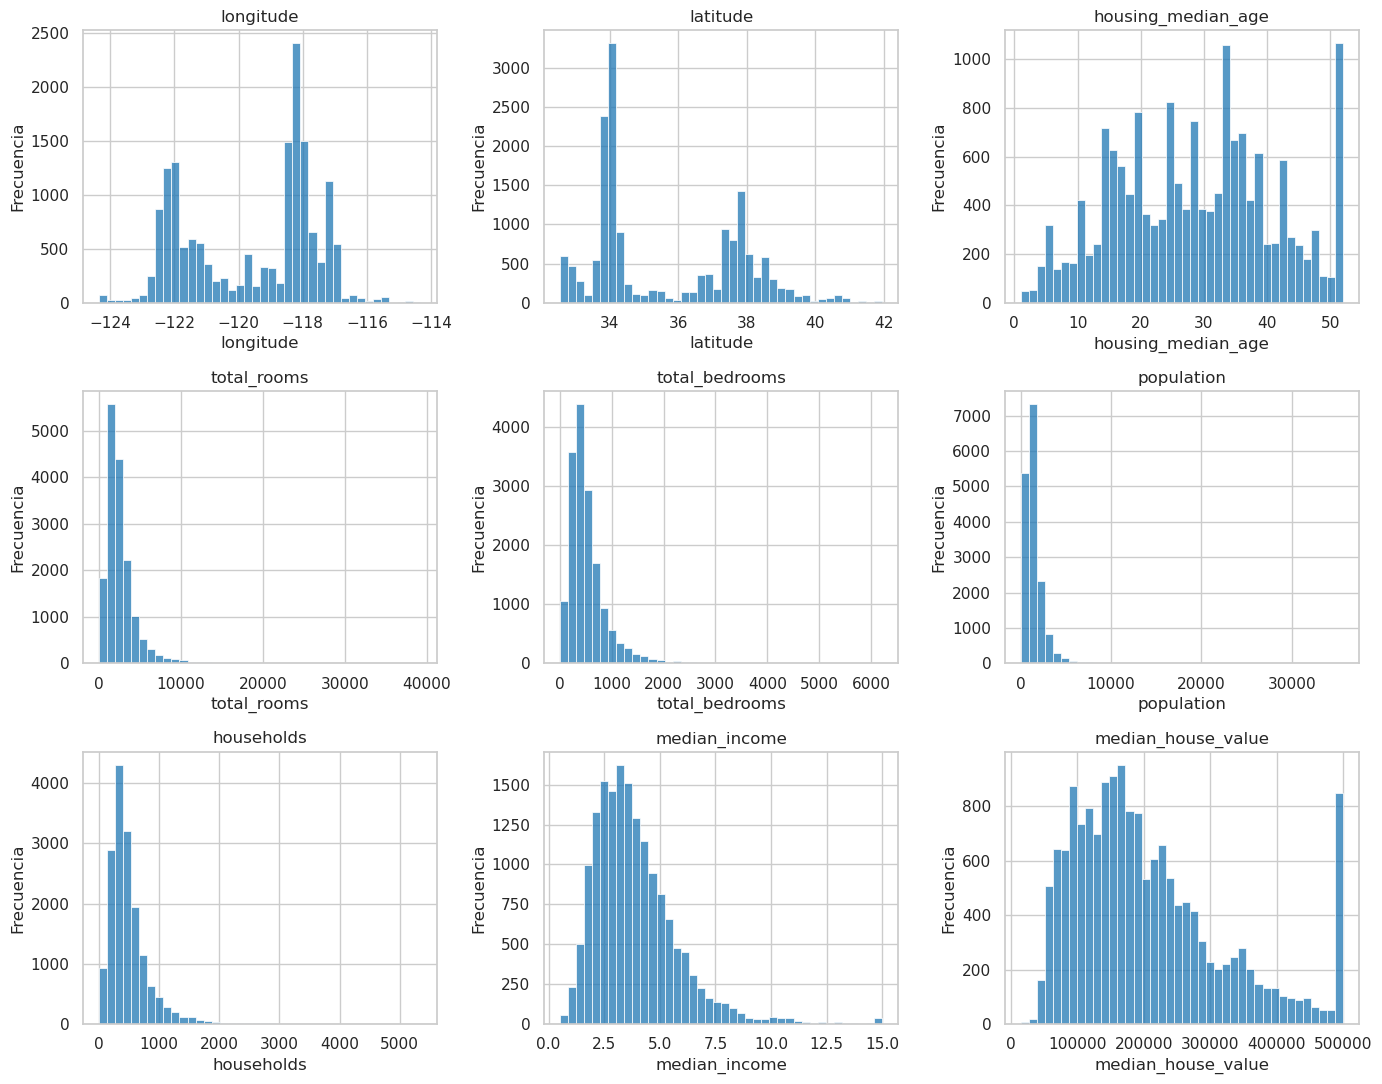

,asimetria
housing_median_age,0.0595
total_rooms,4.0008
total_bedrooms,3.2693
population,4.7416
households,3.2221
median_income,1.6534
median_house_value,0.9868


In [7]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for columna, ax in zip(NUM_ORIGINALES + [OBJETIVO], axes.ravel()):
    sns.histplot(data=df_train, x=columna, bins=40, ax=ax, color='tab:blue')
    ax.set_title(columna)
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()
plt.close(fig)
display(df_train[cols].skew().to_frame('asimetria'))

## 8. Diagrama de caja e interpretación del IQR

La caja va de $Q_1$ a $Q_3$, contiene el 50% central y la línea interna representa la mediana. Con $IQR=Q_3-Q_1$, los límites habituales son $Q_1-1.5IQR$ y $Q_3+1.5IQR$. Los **bigotes no son necesariamente el mínimo y máximo**: llegan hasta los datos más extremos dentro de esos límites. Los puntos externos son candidatos a atípicos, no errores demostrados.

Primero verifico el ejemplo del enunciado y después comparo los precios entre categorías.

Q1=66.0, mediana=70.0, Q3=75.0, IQR=9.0
Límites: [52.5, 88.5]
Candidatos a atípicos: [52 89]


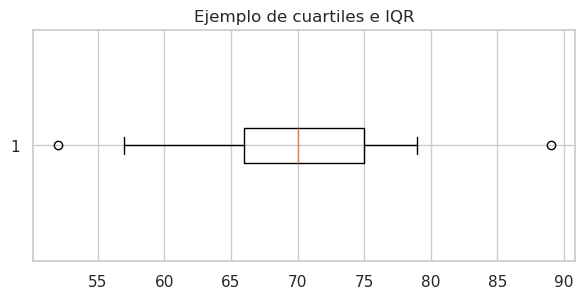

In [8]:
T = np.array([52, 57, 57, 58, 63, 66, 66, 67, 67, 68, 69, 70, 70, 70, 70, 72, 73, 75, 75, 76, 76, 78, 79, 89])
q1, mediana, q3 = np.quantile(T, [0.25, 0.5, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'Q1={q1}, mediana={mediana}, Q3={q3}, IQR={iqr}')
print(f'Límites: [{limite_inferior}, {limite_superior}]')
print('Candidatos a atípicos:', T[(T < limite_inferior) | (T > limite_superior)])
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot(T, vert=False)
ax.set_title('Ejemplo de cuartiles e IQR')
plt.show()
plt.close(fig)

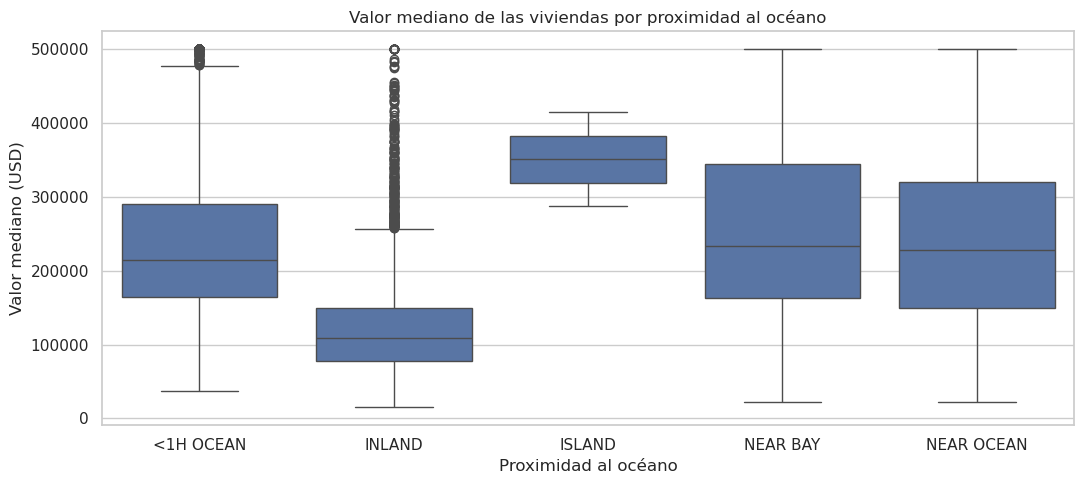

Las cajas muestran diferencias entre grupos, pero pueden estar mezcladas con ingreso, ubicación y tamaño del distrito.


In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df_train, x='ocean_proximity', y=OBJETIVO, order=CATEGORIAS, ax=ax)
ax.set(title='Valor mediano de las viviendas por proximidad al océano', xlabel='Proximidad al océano', ylabel='Valor mediano (USD)')
plt.tight_layout()
plt.show()
plt.close(fig)
print('Las cajas muestran diferencias entre grupos, pero pueden estar mezcladas con ingreso, ubicación y tamaño del distrito.')

## 9. Matriz de correlación

La correlación de Pearson es $r_{xy}=\operatorname{Cov}(x,y)/(s_xs_y)$. Resume asociación lineal y no causalidad. Excluyo la categoría de texto de este cálculo. También reviso pares numéricos muy correlacionados: `total_rooms`, `total_bedrooms`, `population` y `households` comparten información sobre el tamaño del distrito. Esto será importante para PCA y regularización.

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.0000,-0.9245,-0.1058,0.0489,0.0767,0.1081,0.0631,-0.0196,-0.0475
latitude,-0.9245,1.0000,0.0057,-0.0392,-0.0725,-0.1153,-0.0778,-0.0751,-0.1427
housing_median_age,-0.1058,0.0057,1.0000,-0.3645,-0.3251,-0.2987,-0.3065,-0.1113,0.1141
total_rooms,0.0489,-0.0392,-0.3645,1.0000,0.9294,0.8551,0.9184,0.2001,0.1351
total_bedrooms,0.0767,-0.0725,-0.3251,0.9294,1.0000,0.8763,0.9802,-0.0096,0.0478
population,0.1081,-0.1153,-0.2987,0.8551,0.8763,1.0000,0.9046,0.0024,-0.0269
households,0.0631,-0.0778,-0.3065,0.9184,0.9802,0.9046,1.0000,0.0109,0.0646
median_income,-0.0196,-0.0751,-0.1113,0.2001,-0.0096,0.0024,0.0109,1.0000,0.6872
median_house_value,-0.0475,-0.1427,0.1141,0.1351,0.0478,-0.0269,0.0646,0.6872,1.0000


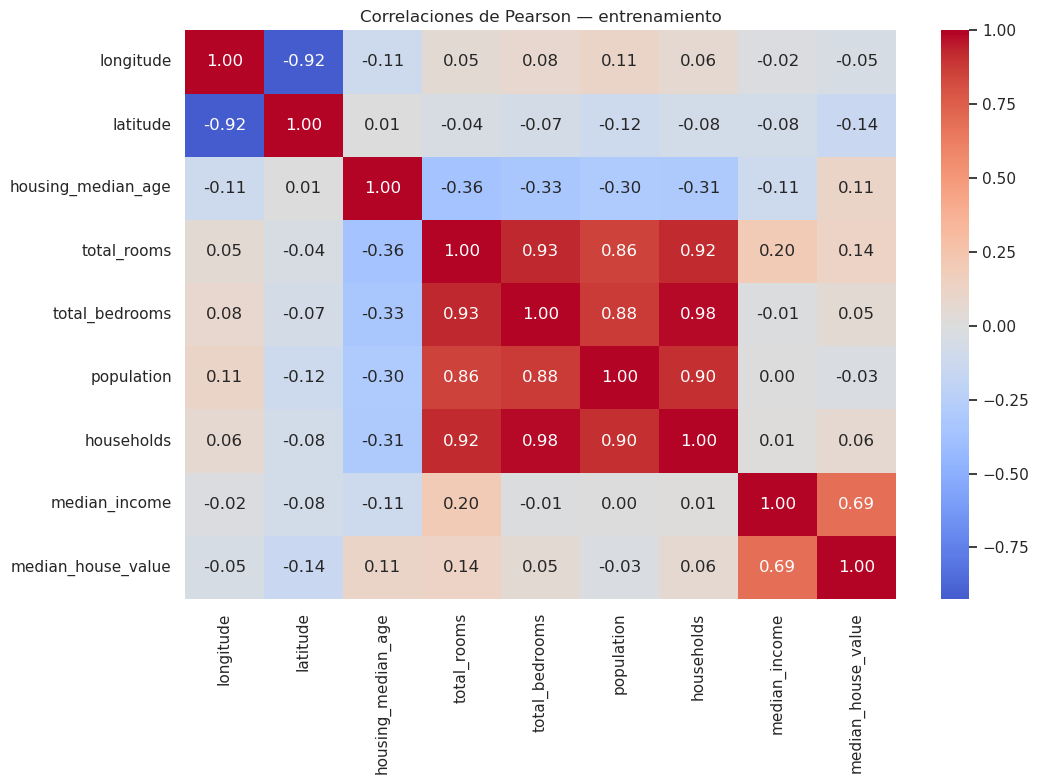

,variable_1,variable_2,correlacion
5,total_bedrooms,households,0.9802
1,total_rooms,total_bedrooms,0.9294
0,longitude,latitude,-0.9245
3,total_rooms,households,0.9184
6,population,households,0.9046
4,total_bedrooms,population,0.8763
2,total_rooms,population,0.8551


,correlacion_con_precio
median_income,0.6872
total_rooms,0.1351
housing_median_age,0.1141
households,0.0646
total_bedrooms,0.0478
population,-0.0269
longitude,-0.0475
latitude,-0.1427


In [10]:
corr_matrix = df_train[NUM_ORIGINALES + [OBJETIVO]].corr()
display(corr_matrix)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlaciones de Pearson — entrenamiento')
plt.tight_layout()
plt.show()
plt.close(fig)
pares = []
for i, a in enumerate(NUM_ORIGINALES):
    for b in NUM_ORIGINALES[i + 1:]:
        if abs(corr_matrix.loc[a, b]) >= 0.75:
            pares.append({'variable_1': a, 'variable_2': b, 'correlacion': corr_matrix.loc[a, b]})
display(pd.DataFrame(pares).sort_values('correlacion', key=lambda s: s.abs(), ascending=False))
display(corr_matrix[OBJETIVO].drop(OBJETIVO).sort_values(ascending=False).to_frame('correlacion_con_precio'))

## 10. Pairplot

Uso exactamente las cuatro columnas solicitadas. Para que el gráfico sea legible tomo una muestra reproducible de 2000 filas de entrenamiento, sin cambiar los datos que se usan para ajustar. El ingreso presenta una relación más clara con el precio que los conteos brutos. El límite superior del precio también se observa aquí.

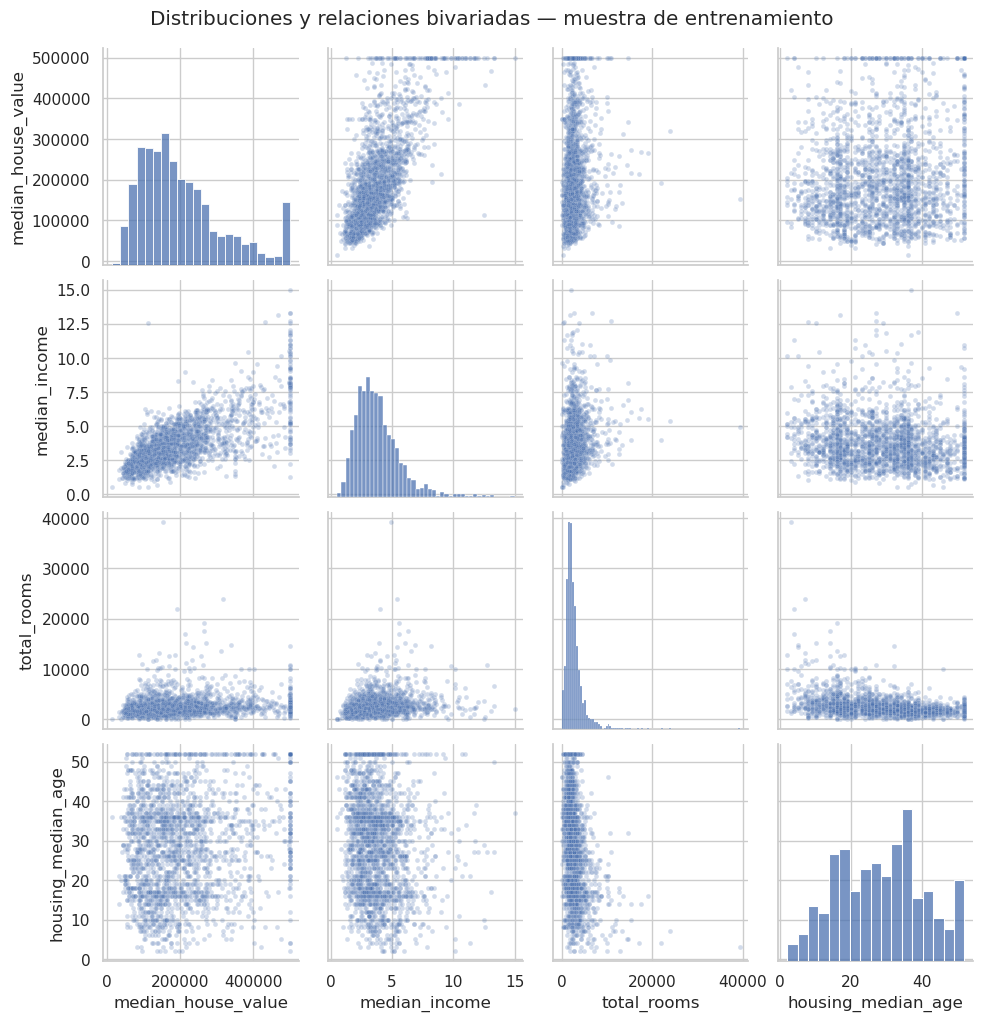

In [11]:
cols_pairplot = [OBJETIVO, 'median_income', 'total_rooms', 'housing_median_age']
muestra_eda = df_train.sample(n=min(2_000, len(df_train)), random_state=SEED)
g = sns.pairplot(muestra_eda[cols_pairplot], diag_kind='hist', plot_kws={'alpha': 0.25, 's': 12})
g.fig.suptitle('Distribuciones y relaciones bivariadas — muestra de entrenamiento', y=1.02)
plt.show()
plt.close(g.fig)

## 11. Scatterplot espacial

Grafico longitud y latitud, usando el valor de la vivienda como color. Así puedo ver patrones geográficos que una sola correlación no resume. Una separación aleatoria mezcla distritos vecinos entre ajuste y prueba: es válida para evaluar nuevos distritos de una distribución parecida, pero puede ser optimista si el objetivo es extrapolar a otra región.

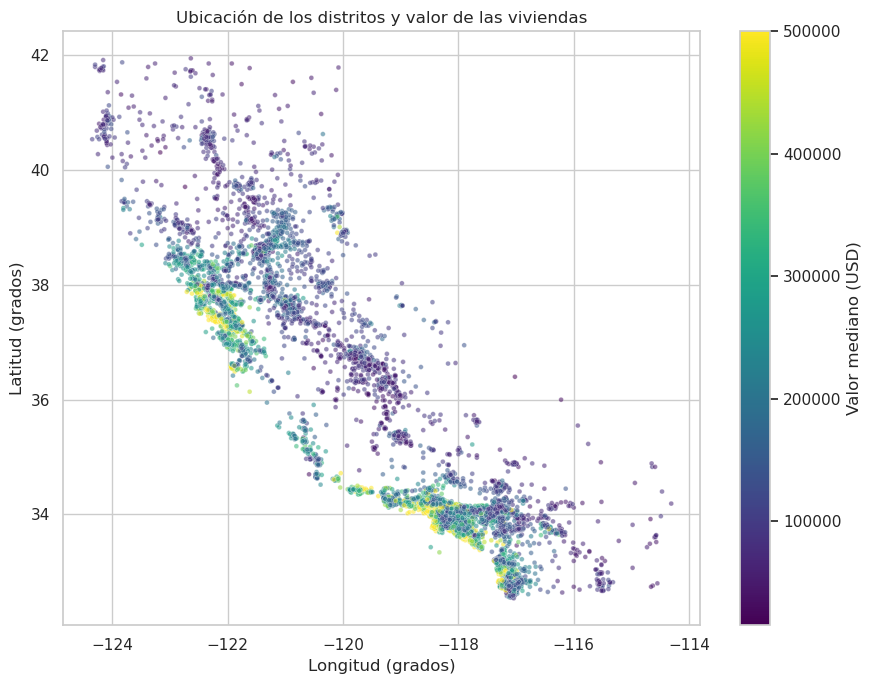

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=df_train, x='longitude', y='latitude', hue=OBJETIVO, palette='viridis', s=12, alpha=0.55, legend=False, ax=ax)
norma = plt.Normalize(df_train[OBJETIVO].min(), df_train[OBJETIVO].max())
fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap='viridis'), ax=ax, label='Valor mediano (USD)')
ax.set(title='Ubicación de los distritos y valor de las viviendas', xlabel='Longitud (grados)', ylabel='Latitud (grados)')
plt.tight_layout()
plt.show()
plt.close(fig)

# 2.0 Preparación del dataframe

## 12–13. ¿Es suficiente la división aleatoria?

`train_test_split(..., test_size=0.2, random_state=42)` sí reserva el 20% y hace reproducible la partición, pero **no garantiza** conservar las proporciones de los grupos de ingreso. La semilla no elimina el *sampling bias*. La estratificación aproxima mejor esas proporciones; tampoco garantiza igualdad en todas las demás variables.

Comparo el muestreo aleatorio con el estratificado. Esta tabla solo verifica el diseño del muestreo: no calcula errores de predicción en prueba ni sirve para elegir modelos.

,Total,Train estratificado,Test estratificado,Test aleatorio,Error aleatorio (%),Error estratificado (%)
median_income,,,,,,
1,0.0398,0.0398,0.0400,0.0402,0.9732,0.3650
2,0.3188,0.3189,0.3188,0.3244,1.7323,0.0152
3,0.3506,0.3506,0.3505,0.3585,2.2664,0.0138
4,0.1763,0.1763,0.1764,0.1674,5.0563,0.0275
5,0.1144,0.1145,0.1143,0.1095,4.3184,0.0847


Error relativo medio aleatorio: 2.869%
Error relativo medio estratificado: 0.101%


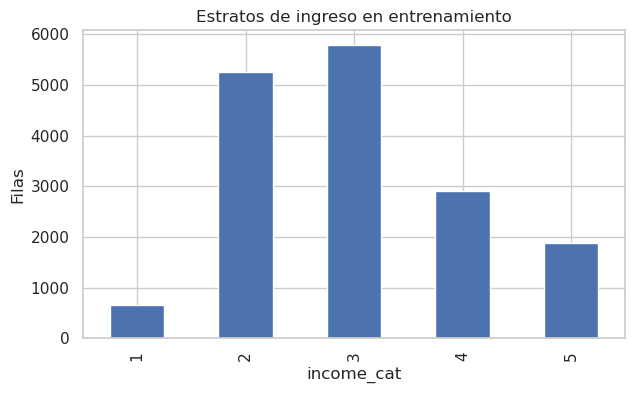

In [13]:
def proporciones_ingreso(indices):
    return income_cat.loc[indices].value_counts(normalize=True).sort_index()

indices_aleatorios_train, indices_aleatorios_test = train_test_split(df.index, test_size=0.20, random_state=SEED)
compare_props = pd.DataFrame({
    'Total': proporciones_ingreso(df.index),
    'Train estratificado': proporciones_ingreso(strat_train_set.index),
    'Test estratificado': proporciones_ingreso(strat_test_set.index),
    'Test aleatorio': proporciones_ingreso(indices_aleatorios_test),
})
compare_props['Error aleatorio (%)'] = abs(100 * compare_props['Test aleatorio'] / compare_props['Total'] - 100)
compare_props['Error estratificado (%)'] = abs(100 * compare_props['Test estratificado'] / compare_props['Total'] - 100)
display(compare_props)
print('Error relativo medio aleatorio: {:.3f}%'.format(compare_props['Error aleatorio (%)'].mean()))
print('Error relativo medio estratificado: {:.3f}%'.format(compare_props['Error estratificado (%)'].mean()))
fig, ax = plt.subplots(figsize=(7, 4))
income_cat.loc[X_train.index].value_counts().sort_index().plot.bar(ax=ax)
ax.set(title='Estratos de ingreso en entrenamiento', xlabel='income_cat', ylabel='Filas')
plt.show()
plt.close(fig)

## 13. Nuevas variables

Los totales mezclan tamaño del distrito y características de sus hogares. Por eso construyo:

$$\text{rooms per household}=\frac{\text{total rooms}}{\text{households}},\quad\text{bedrooms per room}=\frac{\text{total bedrooms}}{\text{total rooms}},\quad\text{population per household}=\frac{\text{population}}{\text{households}}.$$

Estas razones son transformaciones **no lineales**: no equivalen a una combinación lineal de los totales. Las creo con una función para aplicar exactamente el mismo procedimiento a los datos nuevos. Si un denominador fuera cero, dejo `NaN` y lo resuelvo con la imputación de entrenamiento.

In [14]:
def agregar_variables(datos):
    datos = datos.copy()
    datos['rooms_per_household'] = datos['total_rooms'] / datos['households'].replace(0, np.nan)
    datos['bedrooms_per_room'] = datos['total_bedrooms'] / datos['total_rooms'].replace(0, np.nan)
    datos['population_per_household'] = datos['population'] / datos['households'].replace(0, np.nan)
    return datos.replace([np.inf, -np.inf], np.nan)

X_ajuste_variables = agregar_variables(X_ajuste)
display(X_ajuste_variables[NUMERICAS].head())
display(X_ajuste_variables[NUMERICAS].corr()[['median_income', 'rooms_per_household', 'bedrooms_per_room']])
print('Los dormitorios faltantes también generan faltantes en bedrooms_per_room; ambas columnas se imputan dentro del pipeline.')

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household
9464,-123.8400,39.4600,47.0000,"1,150.0000",244.0000,552.0000,201.0000,2.5192,5.7214,0.2122,2.7463
6524,-118.0400,34.0600,30.0000,"2,019.0000",551.0000,"2,481.0000",484.0000,3.1875,4.1715,0.2729,5.1260
20229,-119.3000,34.2700,17.0000,"1,527.0000",503.0000,688.0000,423.0000,1.6007,3.6099,0.3294,1.6265
9193,-119.5300,37.3400,26.0000,"4,047.0000",702.0000,571.0000,199.0000,2.3482,20.3367,0.1735,2.8693
11026,-117.8300,33.8000,30.0000,"4,713.0000",758.0000,"2,271.0000",730.0000,5.8622,6.4562,0.1608,3.1110


,median_income,rooms_per_household,bedrooms_per_room
longitude,-0.0177,-0.0333,0.0940
latitude,-0.0771,0.1129,-0.1155
housing_median_age,-0.1135,-0.1622,0.1410
total_rooms,0.1996,0.1320,-0.1908
total_bedrooms,-0.0076,-0.0024,0.0875
population,0.0038,-0.0744,0.0397
households,0.0116,-0.0834,0.0683
median_income,1.0000,0.3325,-0.6307
rooms_per_household,0.3325,1.0000,-0.4329
bedrooms_per_room,-0.6307,-0.4329,1.0000


Los dormitorios faltantes también generan faltantes en bedrooms_per_room; ambas columnas se imputan dentro del pipeline.


## 14. Limpieza e imputación: media versus mediana

Un `SimpleImputer(strategy='mean')` guarda **medias**, no medianas. La comparación solicitada no debería producir igualdad salvo coincidencia. La mediana es menos sensible a las colas largas, así que la uso para el modelo final. No elimino la columna de dormitorios ni las filas que la tienen incompleta.

El imputador recibe **solo características numéricas**, no el objetivo ni el texto de `ocean_proximity`. En este ejemplo manual lo ajusto con `X_ajuste`; en validación cruzada el pipeline lo vuelve a ajustar dentro de cada fold.

In [15]:
df_train_num = X_ajuste_variables[NUMERICAS]
imp_mean = SimpleImputer(strategy='mean').fit(df_train_num)
imp_median = SimpleImputer(strategy='median').fit(df_train_num)
comparacion_imputacion = pd.DataFrame({
    'media_imputer': imp_mean.statistics_,
    'mediana_pandas': df_train_num.median(),
    'mediana_imputer': imp_median.statistics_,
}, index=NUMERICAS)
display(comparacion_imputacion)
np.testing.assert_allclose(imp_median.statistics_, df_train_num.median().to_numpy())
housing_tr = pd.DataFrame(imp_median.transform(df_train_num), columns=NUMERICAS, index=df_train_num.index)
print('Faltantes después de imputar:', housing_tr.isna().sum().sum())
display(housing_tr.head())

,media_imputer,mediana_pandas,mediana_imputer
longitude,-119.5709,-118.5100,-118.5100
latitude,35.6347,34.2600,34.2600
housing_median_age,28.7247,29.0000,29.0000
total_rooms,"2,625.4201","2,110.0000","2,110.0000"
total_bedrooms,535.3854,431.0000,431.0000
population,"1,421.9025","1,161.0000","1,161.0000"
households,497.6361,407.0000,407.0000
median_income,3.8685,3.5385,3.5385
rooms_per_household,5.4321,5.2342,5.2342
bedrooms_per_room,0.2128,0.2031,0.2031


Faltantes después de imputar: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household
9464,-123.8400,39.4600,47.0000,"1,150.0000",244.0000,552.0000,201.0000,2.5192,5.7214,0.2122,2.7463
6524,-118.0400,34.0600,30.0000,"2,019.0000",551.0000,"2,481.0000",484.0000,3.1875,4.1715,0.2729,5.1260
20229,-119.3000,34.2700,17.0000,"1,527.0000",503.0000,688.0000,423.0000,1.6007,3.6099,0.3294,1.6265
9193,-119.5300,37.3400,26.0000,"4,047.0000",702.0000,571.0000,199.0000,2.3482,20.3367,0.1735,2.8693
11026,-117.8300,33.8000,30.0000,"4,713.0000",758.0000,"2,271.0000",730.0000,5.8622,6.4562,0.1608,3.1110


## 15. Manejo del texto: OneHotEncoder

La codificación one-hot crea indicadores de pertenencia a las categorías. No asigna una distancia ficticia entre ellas. Muestro los cinco indicadores del ejemplo; en las regresiones con intercepto elimino el primero (`<1H OCEAN`) para evitar la dependencia exacta de que todos sumen uno. Sus coeficientes se interpretan respecto a esa referencia.

Mantengo el esquema de categorías del ejercicio incluso si un fold no contiene `ISLAND`. Una categoría conocida con muy pocos datos sigue teniendo un efecto poco confiable. `handle_unknown='ignore'` evita que el pipeline falle ante un texto nuevo, pero no significa que el modelo sepa predecir bien ese caso.

In [16]:
cat_encoder = OneHotEncoder(categories=[CATEGORIAS], sparse_output=False, handle_unknown='ignore')
housing_cat = X_ajuste_variables[['ocean_proximity']]
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
df_cat_1hot = pd.DataFrame(housing_cat_1hot, columns=cat_encoder.get_feature_names_out(), index=housing_cat.index)
print('Categorías del encoder:', cat_encoder.categories_)
display(df_cat_1hot.head())
housing_tr_ = housing_tr.join(df_cat_1hot)
assert housing_tr_.index.equals(X_ajuste.index)
assert housing_tr_.notna().all().all()
print('Conservo el índice al unir para no mezclar las filas después del muestreo.')

Categorías del encoder: [array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
9464,1.0000,0.0000,0.0000,0.0000,0.0000
6524,1.0000,0.0000,0.0000,0.0000,0.0000
20229,0.0000,0.0000,0.0000,0.0000,1.0000
9193,0.0000,1.0000,0.0000,0.0000,0.0000
11026,1.0000,0.0000,0.0000,0.0000,0.0000


Conservo el índice al unir para no mezclar las filas después del muestreo.


## 16. Escalamiento con MinMaxScaler

El escalamiento es $x'=(x-\min_{train})/(\max_{train}-\min_{train})$. Para la regresión lineal inicial uso `MinMaxScaler` como propone el enunciado; escalo solo las numéricas, porque los indicadores ya están en 0/1.

No escalo el objetivo con este objeto. Ajustar el escalador con validación o prueba sería una fuga de información. Un dato nuevo fuera del rango de entrenamiento puede transformarse a un valor menor que 0 o mayor que 1: eso no es un error del escalador. Para PCA revisaré otra elección de escala.

In [17]:
scaler = MinMaxScaler().fit(housing_tr)
housing_prepared = pd.DataFrame(scaler.transform(housing_tr), columns=NUMERICAS, index=housing_tr.index).join(df_cat_1hot)
display(housing_prepared.head())
display(housing_prepared[NUMERICAS].agg(['min', 'max']).T)
print('Esta preparación manual explica cada paso. Para los modelos uso un pipeline que repite los ajustes correctamente.')

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
9464,0.0460,0.7354,0.9020,0.0291,0.0390,0.0154,0.0372,0.1393,0.0317,0.1364,0.0016,1.0000,0.0000,0.0000,0.0000,0.0000
6524,0.6266,0.1615,0.5686,0.0512,0.0884,0.0695,0.0900,0.1853,0.0207,0.2102,0.0035,1.0000,0.0000,0.0000,0.0000,0.0000
20229,0.5005,0.1838,0.3137,0.0387,0.0807,0.0192,0.0786,0.0759,0.0167,0.2789,0.0007,0.0000,0.0000,0.0000,0.0000,1.0000
9193,0.4775,0.5101,0.4902,0.1028,0.1128,0.0159,0.0368,0.1275,0.1356,0.0893,0.0017,0.0000,1.0000,0.0000,0.0000,0.0000
11026,0.6476,0.1339,0.5686,0.1197,0.1218,0.0636,0.1359,0.3698,0.0369,0.0740,0.0019,1.0000,0.0000,0.0000,0.0000,0.0000


,min,max
longitude,0.0000,1.0000
latitude,0.0000,1.0000
housing_median_age,0.0000,1.0000
total_rooms,0.0000,1.0000
total_bedrooms,0.0000,1.0000
population,0.0000,1.0000
households,0.0000,1.0000
median_income,0.0000,1.0000
rooms_per_household,0.0000,1.0000
bedrooms_per_room,0.0000,1.0000


Esta preparación manual explica cada paso. Para los modelos uso un pipeline que repite los ajustes correctamente.


## 17. Procedimiento ordenado y regresión lineal

El orden es **separar → crear razones → imputar → codificar/escalar → ajustar**. `ColumnTransformer` separa las ramas numérica y categórica. `Pipeline` mantiene todas las transformaciones dentro de cada ajuste.

Primero evalúo el ajuste lineal en la validación interna. También uso un modelo que siempre predice la media como referencia: un modelo útil debería mejorar esa predicción trivial. Más adelante se vuelven a ajustar los candidatos finales con todo `X_train`.

In [18]:
def rama_categorica():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(categories=[CATEGORIAS], drop='first', handle_unknown='ignore', sparse_output=False)),
    ])

def crear_modelo_lineal():
    preparacion = ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', MinMaxScaler())]), NUMERICAS),
        ('cat', rama_categorica(), ['ocean_proximity']),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ('variables', FunctionTransformer(agregar_variables)),
        ('preparacion', preparacion),
        ('modelo', LinearRegression()),
    ])

def metricas(y_real, prediccion):
    return {
        'RMSE (USD)': root_mean_squared_error(y_real, prediccion) * UNIDAD_Y,
        'MAE (USD)': mean_absolute_error(y_real, prediccion) * UNIDAD_Y,
        'R2': r2_score(y_real, prediccion),
    }

with threadpool_limits(limits=1):
    lineal_validacion = crear_modelo_lineal().fit(X_ajuste, y_ajuste)
    referencia = DummyRegressor(strategy='mean').fit(X_ajuste, y_ajuste)
resultado_inicial = pd.DataFrame({
    'Lineal — ajuste': metricas(y_ajuste, lineal_validacion.predict(X_ajuste)),
    'Lineal — validación': metricas(y_validacion, lineal_validacion.predict(X_validacion)),
    'Media — validación': metricas(y_validacion, referencia.predict(X_validacion)),
}).T
display(resultado_inicial)

,RMSE (USD),MAE (USD),R2
Lineal — ajuste,"68,179.5718","49,198.1169",0.6520
Lineal — validación,"68,269.9453","48,675.2637",0.6540
Media — validación,"116,056.3395","90,451.2315",-0.0000


In [19]:
with threadpool_limits(limits=1):
    modelo_lineal = crear_modelo_lineal().fit(X_train, y_train)
preparacion_lineal = modelo_lineal.named_steps['preparacion']
nombres_lineales = preparacion_lineal.get_feature_names_out()
housing_train = pd.DataFrame(
    preparacion_lineal.transform(agregar_variables(X_train)),
    columns=nombres_lineales, index=X_train.index,
)
housing_train[OBJETIVO] = strat_train_set[OBJETIVO]
assert 'income_cat' not in housing_train.columns
assert OBJETIVO not in nombres_lineales
assert np.isfinite(housing_train.to_numpy()).all()
print('housing_train preparado y etiquetado:', housing_train.shape)
display(housing_train.head())
print('housing_test se construye en la comparación final, sin reajustar la preparación con prueba.')

housing_train preparado y etiquetado: (16512, 16)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,median_house_value
12655,0.2878,0.6355,0.5490,0.0984,0.1281,0.0626,0.1314,0.1154,0.0309,0.1175,0.0020,1.0000,0.0000,0.0000,0.0000,"72,100.0000"
15502,0.7092,0.0584,0.1176,0.1352,0.1374,0.0564,0.1430,0.4026,0.0412,0.0675,0.0016,0.0000,0.0000,0.0000,1.0000,"279,600.0000"
2908,0.5289,0.3007,0.8431,0.0410,0.0496,0.0186,0.0556,0.1638,0.0303,0.1018,0.0012,1.0000,0.0000,0.0000,0.0000,"82,700.0000"
14053,0.7191,0.0223,0.4510,0.0476,0.0833,0.0251,0.0898,0.1191,0.0196,0.1961,0.0009,0.0000,0.0000,0.0000,1.0000,"112,500.0000"
20496,0.5627,0.1849,0.5098,0.0898,0.1037,0.0514,0.1079,0.2756,0.0353,0.0919,0.0020,0.0000,0.0000,0.0000,0.0000,"238,300.0000"


housing_test se construye en la comparación final, sin reajustar la preparación con prueba.


## 18–22. Interpretación del modelo inicial

**18. ¿Qué concluyo?** La regresión lineal sirve como referencia sencilla. Comparo sus errores de ajuste y validación, y si mejora la predicción de la media. Un error bajo solo en ajuste no demostraría generalización.

**19. ¿Es válida la regresión lineal?** Se puede ajustar como predictor, pero eso no demuestra que el precio sea una función realmente lineal ni que se cumplan los supuestos de inferencia clásica. Las colas, la geografía, el tope del precio y la posible heterocedasticidad limitan el modelo. Los residuos ayudan a revisar sus errores.

**20. ¿Qué informa el score?** Para `LinearRegression`, `score` es

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

$R^2=1$ representa predicción perfecta; $R^2=0$ equivale a predecir la media del conjunto evaluado y puede ser negativo. **No es un porcentaje de aciertos**. MAE y RMSE complementan el score porque expresan la magnitud del error en USD.

**21. ¿Puedo ajustar otro modelo?** Sí: un modelo con PCA para reducir variables, o términos polinomiales con Ridge/Lasso para controlar la complejidad. La comparación debe usar validación, no elegir por el mejor error de entrenamiento.

**22. ¿Cómo automatizo?** El pipeline anterior recibe las columnas originales y hace la misma preparación antes de `fit` o `predict`. En validación cruzada no debo pasarle una matriz que haya sido imputada o escalada previamente con todos los datos.

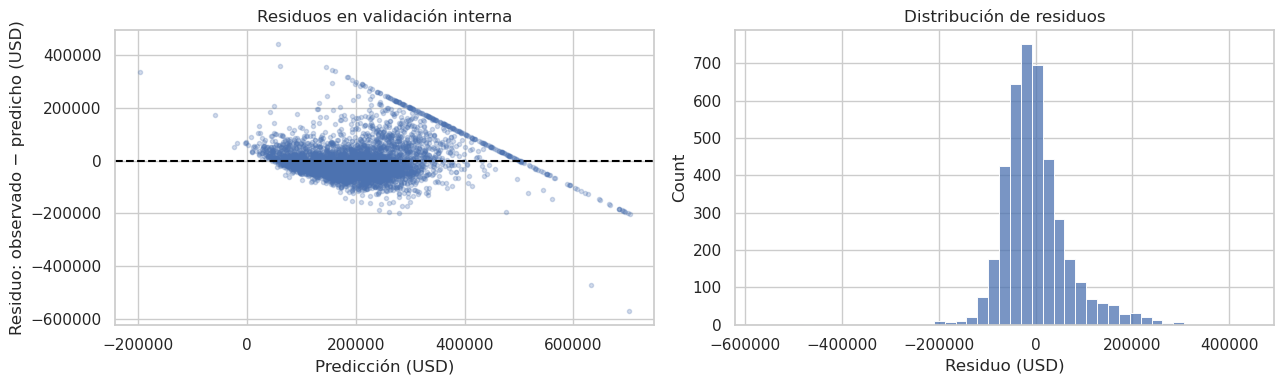

Score de validación: 0.6540
Una estructura en los residuos señala información que la forma lineal no recupera; no la interpreto como evidencia causal.


In [20]:
pred_validacion_lineal = lineal_validacion.predict(X_validacion)
residuos_validacion = (y_validacion - pred_validacion_lineal) * UNIDAD_Y
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(pred_validacion_lineal * UNIDAD_Y, residuos_validacion, s=9, alpha=0.25)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Predicción (USD)', ylabel='Residuo: observado − predicho (USD)', title='Residuos en validación interna')
sns.histplot(residuos_validacion, bins=45, ax=axes[1])
axes[1].set(title='Distribución de residuos', xlabel='Residuo (USD)')
plt.tight_layout()
plt.show()
plt.close(fig)
print(f'Score de validación: {lineal_validacion.score(X_validacion, y_validacion):.4f}')
print('Una estructura en los residuos señala información que la forma lineal no recupera; no la interpreto como evidencia causal.')

# 3.0 Modelo reducido con PCA — punto 23

## 23.1. De la matriz de covarianzas a las componentes

PCA encuentra direcciones de máxima varianza de las características, **sin usar el precio**. Para una matriz centrada $Z$:

$$C=\frac{1}{n-1}Z^TZ,\qquad Cv_j=\lambda_jv_j,\qquad PC_j=Zv_j.$$

Ordeno los autovalores de mayor a menor y comparo el cálculo con `PCA`. Uso **StandardScaler**, no MinMax, para que las variables contribuyan según variaciones relativas a su desviación estándar. MinMax no iguala varianzas y su rango es sensible a extremos. StandardScaler tampoco elimina atípicos: es una decisión de escala, no una limpieza robusta.

El PCA usa las **mismas 11 variables numéricas de la regresión inicial**, incluidas las tres razones. La categoría no entra a PCA: mantengo sus cuatro indicadores por separado.

In [21]:
pre_pca_exploratorio = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
]).fit(X_ajuste_variables[NUMERICAS])
Z = pre_pca_exploratorio.transform(X_ajuste_variables[NUMERICAS])
covarianza = np.cov(Z, rowvar=False)
autovalores, autovectores = np.linalg.eigh(covarianza)
orden = np.argsort(autovalores)[::-1]
autovalores, autovectores = autovalores[orden], autovectores[:, orden]
pca_completo = PCA(svd_solver='full').fit(Z)
np.testing.assert_allclose(autovalores, pca_completo.explained_variance_, atol=1e-10)
alineacion = abs(np.diag(autovectores.T @ pca_completo.components_.T))
np.testing.assert_allclose(alineacion, np.ones(len(NUMERICAS)), atol=1e-8)
print('Autovalores de covarianza y PCA coinciden. El signo de cada autovector puede cambiar sin cambiar la componente.')
display(pd.DataFrame(covarianza, index=NUMERICAS, columns=NUMERICAS))
varianza_pca = pd.DataFrame({
    'autovalor': autovalores,
    'varianza_explicada': pca_completo.explained_variance_ratio_,
    'varianza_acumulada': np.cumsum(pca_completo.explained_variance_ratio_),
}, index=[f'PC{i+1}' for i in range(len(NUMERICAS))])
display(varianza_pca)

Autovalores de covarianza y PCA coinciden. El signo de cada autovector puede cambiar sin cambiar la componente.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household
longitude,1.0001,-0.9242,-0.1065,0.0467,0.0736,0.1043,0.0613,-0.0177,-0.0333,0.0936,-0.0034
latitude,-0.9242,1.0001,0.0069,-0.0380,-0.0706,-0.1122,-0.0762,-0.0771,0.1129,-0.1150,0.0092
housing_median_age,-0.1065,0.0069,1.0001,-0.3681,-0.3265,-0.2983,-0.3088,-0.1135,-0.1622,0.1403,0.0173
total_rooms,0.0467,-0.0380,-0.3681,1.0001,0.9272,0.8553,0.9209,0.1997,0.1320,-0.1900,-0.0250
total_bedrooms,0.0736,-0.0706,-0.3265,0.9272,1.0001,0.8716,0.9759,-0.0075,-0.0022,0.0879,-0.0284
population,0.1043,-0.1122,-0.2983,0.8553,0.8716,1.0001,0.9029,0.0038,-0.0744,0.0394,0.0832
households,0.0613,-0.0762,-0.3088,0.9209,0.9759,0.9029,1.0001,0.0116,-0.0834,0.0679,-0.0276
median_income,-0.0177,-0.0771,-0.1135,0.1997,-0.0075,0.0038,0.0116,1.0001,0.3325,-0.6272,0.0267
rooms_per_household,-0.0333,0.1129,-0.1622,0.1320,-0.0022,-0.0744,-0.0834,0.3325,1.0001,-0.4321,-0.0049
bedrooms_per_room,0.0936,-0.1150,0.1403,-0.1900,0.0879,0.0394,0.0679,-0.6272,-0.4321,1.0001,0.0037


,autovalor,varianza_explicada,varianza_acumulada
PC1,3.9064,0.3551,0.3551
PC2,2.1160,0.1923,0.5475
PC3,1.8335,0.1667,0.7141
PC4,1.0154,0.0923,0.8064
PC5,0.8488,0.0772,0.8836
PC6,0.6720,0.0611,0.9447
PC7,0.3615,0.0329,0.9775
PC8,0.1364,0.0124,0.9899
PC9,0.0558,0.0051,0.9950
PC10,0.0394,0.0036,0.9986


## 23.2. ¿Cuántas componentes conservo?

Conservo **tres componentes numéricas** como compromiso explícito de reducción: paso de 11 numéricas a 3, manteniendo los cuatro indicadores categóricos. El modelo reducido tiene entonces **7 entradas, no solo 3**. Registro cuánta varianza retienen esas componentes y también cuántas serían necesarias para llegar al 90%.

No afirmo que tres sea el número óptimo para predecir: una dirección con poca varianza puede ser importante para el precio. Este número queda fijo por el objetivo de simplicidad, sin seleccionar `k` con el objetivo; esto también permite hacer después un test de permutaciones de una regla de modelado predefinida.

Tres componentes retienen 71.41% de la varianza numérica; para 90% necesitaría 6.


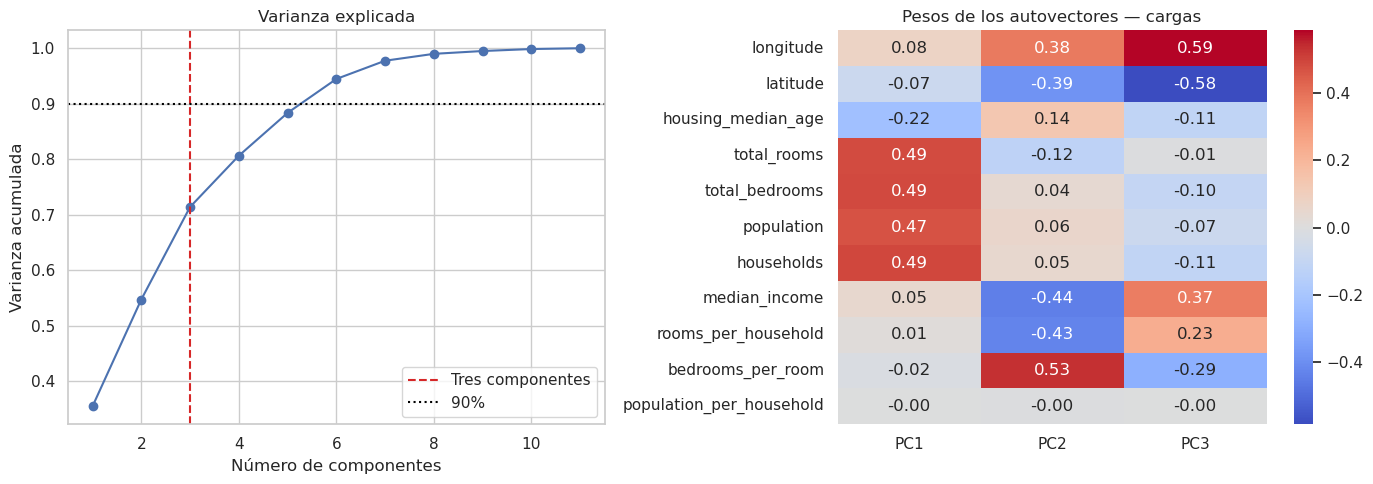

PC1: mayores pesos en households, total_bedrooms, total_rooms, population.
PC2: mayores pesos en bedrooms_per_room, median_income, rooms_per_household, latitude.
PC3: mayores pesos en longitude, latitude, median_income, bedrooms_per_room.


In [22]:
K_PCA = 3
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)
k_90 = np.searchsorted(varianza_acumulada, 0.90) + 1
print(f'Tres componentes retienen {varianza_acumulada[K_PCA-1]:.2%} de la varianza numérica; para 90% necesitaría {k_90}.')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(np.arange(1, len(NUMERICAS)+1), varianza_acumulada, 'o-')
axes[0].axvline(K_PCA, color='tab:red', linestyle='--', label='Tres componentes')
axes[0].axhline(0.90, color='black', linestyle=':', label='90%')
axes[0].set(xlabel='Número de componentes', ylabel='Varianza acumulada', title='Varianza explicada')
axes[0].legend()
cargas = pd.DataFrame(pca_completo.components_[:K_PCA].T, index=NUMERICAS, columns=['PC1', 'PC2', 'PC3'])
sns.heatmap(cargas, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Pesos de los autovectores — cargas')
plt.tight_layout()
plt.show()
plt.close(fig)
for pc in cargas:
    principales = cargas[pc].abs().nlargest(4).index
    print('{}: mayores pesos en {}.'.format(pc, ', '.join(principales)))

### Interpretación de las cargas

Relaciono los grupos de pesos con la correlación y el pairplot: los conteos correlacionados pueden resumirse en una dirección de **tamaño del distrito**; longitud y latitud resumen **ubicación**; ingreso y razones describen **condiciones de los hogares**. La tabla anterior permite comprobar qué variables dominan realmente cada componente; el orden y el signo no son etiquetas físicas universales.

Aquí llamo cargas a los pesos `components_`. Si quisiera cargas expresadas como correlaciones con las variables tendría que incorporar la escala de los autovalores. PCA no demuestra que una componente cause el precio.

In [23]:
def crear_modelo_pca(numericas=NUMERICAS):
    preparacion = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=K_PCA, svd_solver='full')),
        ]), numericas),
        ('cat', rama_categorica(), ['ocean_proximity']),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ('variables', FunctionTransformer(agregar_variables)),
        ('preparacion', preparacion),
        ('modelo', LinearRegression()),
    ])

with threadpool_limits(limits=1):
    pca_validacion = crear_modelo_pca().fit(X_ajuste, y_ajuste)
    modelo_pca = crear_modelo_pca().fit(X_train, y_train)
comparacion_reduccion = pd.DataFrame({
    'Lineal completa': metricas(y_validacion, pred_validacion_lineal),
    'PCA (3 PC + 4 indicadores)': metricas(y_validacion, pca_validacion.predict(X_validacion)),
}).T
display(comparacion_reduccion)
perdida_r2_validacion = comparacion_reduccion.loc['Lineal completa', 'R2'] - comparacion_reduccion.loc['PCA (3 PC + 4 indicadores)', 'R2']
print(f'R2 perdido por reducir en validación: {perdida_r2_validacion:+.4f} puntos de R2.')

,RMSE (USD),MAE (USD),R2
Lineal completa,"68,269.9453","48,675.2637",0.6540
PCA (3 PC + 4 indicadores),"88,395.2729","64,319.1255",0.4199


R2 perdido por reducir en validación: +0.2341 puntos de R2.


## 23.3. ¿Las razones aportan algo que PCA no captura?

PCA sobre los totales solo construye combinaciones lineales; no puede reconstruir exactamente una división como habitaciones por hogar. Para revisar su aporte comparo **PCA con las ocho numéricas originales** contra **PCA con originales más razones**, conservando tres componentes y las mismas particiones de validación cruzada.

Esta comparación indica utilidad predictiva en esta configuración, no información causal nueva ni una garantía de mejora para cualquier modelo. No uso prueba para decidir si conservarlas.

In [24]:
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
filas_ablacion = []
with threadpool_limits(limits=1):
    for nombre, numericas in [('PCA sin razones', NUM_ORIGINALES), ('PCA con razones', NUMERICAS)]:
        scores = cross_validate(
            crear_modelo_pca(numericas), X_train, y_train, cv=cv,
            scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}, n_jobs=1,
        )
        filas_ablacion.append({
            'Modelo': nombre, 'RMSE CV (USD)': -scores['test_rmse'].mean()*UNIDAD_Y,
            'Desv. RMSE CV (USD)': scores['test_rmse'].std()*UNIDAD_Y, 'R2 CV': scores['test_r2'].mean(),
        })
ablacion_ratios = pd.DataFrame(filas_ablacion).set_index('Modelo')
display(ablacion_ratios)
mejora_ratios = ablacion_ratios.loc['PCA sin razones', 'RMSE CV (USD)'] - ablacion_ratios.loc['PCA con razones', 'RMSE CV (USD)']
print(f'Cambio de RMSE CV al añadir razones: {mejora_ratios:+,.0f} USD de mejora (negativo = empeora).')

,RMSE CV (USD),Desv. RMSE CV (USD),R2 CV
Modelo,,,
PCA sin razones,"81,065.0156","1,819.3488",0.5090
PCA con razones,"86,306.3555","1,167.6373",0.4434


Cambio de RMSE CV al añadir razones: -5,241 USD de mejora (negativo = empeora).


## 23.4. Test de permutaciones

La hipótesis nula es que no existe asociación predictiva entre las características y el precio bajo el supuesto de intercambio de etiquetas entre distritos. Permuto `y_train` y repito validación cruzada con **todo el pipeline**, incluyendo imputación, escala y PCA. No permuto las etiquetas de prueba.

Uso 199 permutaciones: el menor p-valor posible es $1/200=0.005$. El cálculo es $(1+\#\{score_{perm}\ge score_{real}\})/(B+1)$. El número de componentes ya estaba fijado; no selecciono hiperparámetros usando las etiquetas antes de este test. Un resultado significativo demuestra asociación predictiva bajo estos supuestos, no causalidad. La dependencia espacial puede invalidar la intercambiabilidad y exigir permutaciones por bloques.

R2 medio CV real: 0.4434
R2 medio bajo permutaciones: -0.0008
p-valor de permutación: 0.0050
Hay evidencia de asociación predictiva.


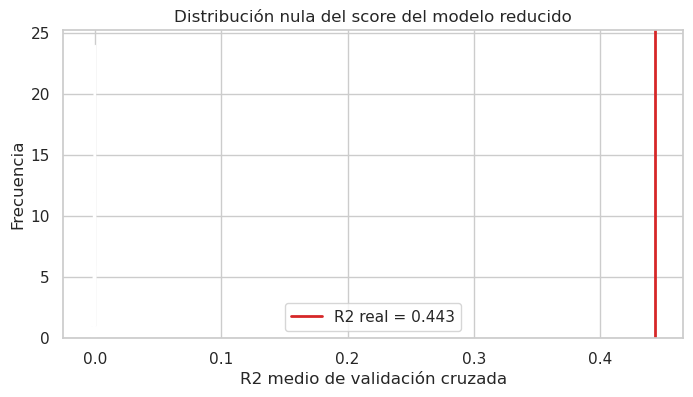

In [25]:
with threadpool_limits(limits=1):
    score_real, scores_permutados, p_permutacion = permutation_test_score(
        crear_modelo_pca(), X_train, y_train, scoring='r2', cv=cv,
        n_permutations=N_PERMUTACIONES, random_state=SEED, n_jobs=1,
    )
print(f'R2 medio CV real: {score_real:.4f}')
print(f'R2 medio bajo permutaciones: {scores_permutados.mean():.4f}')
print(f'p-valor de permutación: {p_permutacion:.4f}')
print('Hay evidencia de asociación predictiva.' if p_permutacion < 0.05 else 'No hay evidencia suficiente de asociación con este test.')
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(scores_permutados, bins=25, ax=ax)
ax.axvline(score_real, color='tab:red', linewidth=2, label=f'R2 real = {score_real:.3f}')
ax.set(title='Distribución nula del score del modelo reducido', xlabel='R2 medio de validación cruzada', ylabel='Frecuencia')
ax.legend()
plt.show()
plt.close(fig)

## 23.5. Coeficientes e interpretabilidad

Comparo los coeficientes usando modelos ajustados con todo entrenamiento. Los coeficientes de MinMax y de PCA están en escalas diferentes, así que no comparo sus magnitudes directamente. Para las numéricas expreso el efecto del lineal por una desviación estándar y reconstruyo el efecto del reducido sobre las variables estandarizadas con $\beta_Z=V_k^T\beta_{PC}$.

El reducido tiene menos coeficientes, pero cada componente mezcla varias variables. Para una persona no especialista, las variables originales pueden ser más fáciles de explicar. Menos dimensiones no significa automáticamente más interpretabilidad ni que los coeficientes representen efectos causales.

In [26]:
rama_pca_final = modelo_pca.named_steps['preparacion'].named_transformers_['num']
pca_final = rama_pca_final.named_steps['pca']
escala_std = rama_pca_final.named_steps['scaler'].scale_
escala_minmax = preparacion_lineal.named_transformers_['num'].named_steps['scaler'].scale_
beta_lineal = modelo_lineal.named_steps['modelo'].coef_[:len(NUMERICAS)]
beta_pc = modelo_pca.named_steps['modelo'].coef_[:K_PCA]
beta_reconstruido = pca_final.components_.T @ beta_pc
comparacion_coef = pd.DataFrame({
    'Lineal: USD por 1 std': beta_lineal * escala_minmax * escala_std * UNIDAD_Y,
    'PCA reconstruido: USD por 1 std': beta_reconstruido * UNIDAD_Y,
}, index=NUMERICAS)
display(comparacion_coef)
display(pd.Series(beta_pc*UNIDAD_Y, index=['PC1', 'PC2', 'PC3'], name='USD por unidad de PC').to_frame())
print('Las variables colineales pueden redistribuir coeficientes sin cambiar mucho las predicciones.')

,Lineal: USD por 1 std,PCA reconstruido: USD por 1 std
longitude,"-56,046.3390",405.6928
latitude,"-56,657.8288",-87.9269
housing_median_age,"13,931.5694","-7,406.0003"
total_rooms,"7,996.0630","5,792.7796"
total_bedrooms,322.8038,"-1,283.8993"
population,"-46,114.1637","-1,338.5020"
households,"42,894.5071","-1,704.9216"
median_income,"78,265.1599","21,786.7289"
rooms_per_household,"7,278.0069","17,796.2797"
bedrooms_per_room,"16,859.1862","-22,788.2017"


,USD por unidad de PC
PC1,"4,015.2657"
PC2,"-29,900.0266"
PC3,"22,258.9843"


Las variables colineales pueden redistribuir coeficientes sin cambiar mucho las predicciones.


# 4.0 Regularización: L2 versus L1 — punto 24

## 24.1. Aumentar la complejidad hasta observar sobreajuste

Ahora agrego términos polinomiales. Para controlar las colas antes de potenciarlas aplico `log1p` a los conteos y las razones; longitud, latitud, edad e ingreso permanecen en su escala original. Esta transformación conserva el orden pero cambia la forma funcional del modelo.

El pipeline **imputa → estandariza → genera potencias/interacciones → estandariza los términos**. Los indicadores categóricos se dejan aparte. Para el experimento de sobreajuste fijo una muestra de **800 filas de ajuste**, igual para todos los grados, y evalúo siempre en la misma validación interna. Comparo grados 1–4: en grado 4 hay más términos que observaciones y el ajuste puede prácticamente interpolar. Esto es un experimento controlado con pocos datos, no una afirmación de que cualquier polinomio sobre todo entrenamiento sobreajuste.

In [27]:
LOG_COLUMNAS = ['total_rooms', 'total_bedrooms', 'population', 'households'] + RATIOS

def log_variables(datos):
    datos = datos.copy()
    datos[LOG_COLUMNAS] = np.log1p(datos[LOG_COLUMNAS])
    return datos

def crear_modelo_polinomial(grado=2, regresor=None):
    if regresor is None:
        regresor = LinearRegression()
    preparacion = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('poly', PolynomialFeatures(degree=grado, include_bias=False)),
            ('scaler_poly', StandardScaler()),
        ]), NUMERICAS),
        ('cat', rama_categorica(), ['ocean_proximity']),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ('variables', FunctionTransformer(agregar_variables)),
        ('logaritmos', FunctionTransformer(log_variables)),
        ('preparacion', preparacion),
        ('modelo', regresor),
    ])

X_pequeno, _, y_pequeno, _ = train_test_split(X_ajuste, y_ajuste, train_size=800, random_state=SEED)
filas_grados, modelos_grados = [], {}
with threadpool_limits(limits=1):
    for grado in [1, 2, 3, 4]:
        modelo = crear_modelo_polinomial(grado).fit(X_pequeno, y_pequeno)
        modelos_grados[grado] = modelo
        filas_grados.append({
            'grado': grado, 'terminos': len(modelo.named_steps['modelo'].coef_),
            'RMSE ajuste (USD)': root_mean_squared_error(y_pequeno, modelo.predict(X_pequeno))*UNIDAD_Y,
            'RMSE validacion (USD)': root_mean_squared_error(y_validacion, modelo.predict(X_validacion))*UNIDAD_Y,
        })
experimento_grados = pd.DataFrame(filas_grados).set_index('grado')
lineal_pequeno = crear_modelo_lineal().fit(X_pequeno, y_pequeno)
error_lineal_pequeno = root_mean_squared_error(y_validacion, lineal_pequeno.predict(X_validacion))*UNIDAD_Y
display(experimento_grados)
print(f'Regresión original sobre las mismas 800 filas: RMSE validación = {error_lineal_pequeno:,.0f} USD.')

,terminos,RMSE ajuste (USD),RMSE validacion (USD)
grado,,,
1,15,"63,097.7951","66,175.4439"
2,81,"53,139.6197","210,947.5885"
3,367,"37,610.3440","130,386,176.7535"
4,1368,0.0000,"412,057,876.3674"


Regresión original sobre las mismas 800 filas: RMSE validación = 68,804 USD.


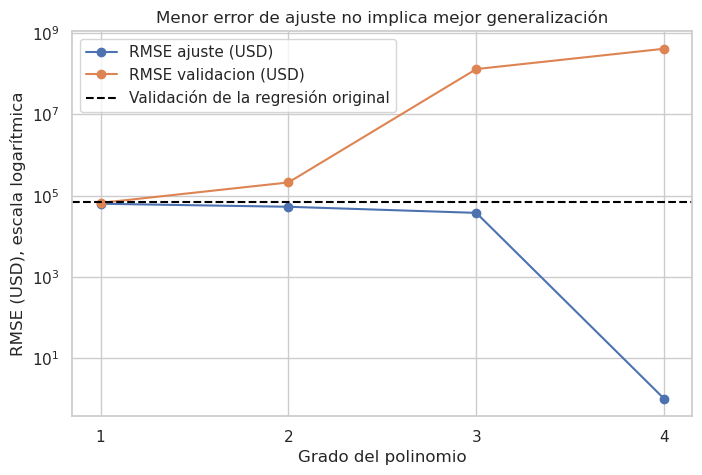

El grado 4 casi anula el error de ajuste, pero el de validación crece: esa brecha evidencia sobreajuste.
Para visualizar, los RMSE menores que 1 USD se dibujan en 1; la tabla conserva el valor real.


In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
for columna in ['RMSE ajuste (USD)', 'RMSE validacion (USD)']:
    ax.semilogy(experimento_grados.index, experimento_grados[columna].clip(lower=1), 'o-', label=columna)
ax.axhline(error_lineal_pequeno, linestyle='--', color='black', label='Validación de la regresión original')
ax.set(xlabel='Grado del polinomio', ylabel='RMSE (USD), escala logarítmica', title='Menor error de ajuste no implica mejor generalización')
ax.set_xticks([1, 2, 3, 4])
ax.legend()
plt.show()
plt.close(fig)
print('El grado 4 casi anula el error de ajuste, pero el de validación crece: esa brecha evidencia sobreajuste.')
print('Para visualizar, los RMSE menores que 1 USD se dibujan en 1; la tabla conserva el valor real.')

## 24.2. ¿Cómo cambia el gradiente con L2?

Para $m$ observaciones, considerando el intercepto por separado:

$$J_{L2}(\theta)=\frac{1}{2m}\|X\theta-y\|_2^2+\frac{\lambda}{2}\sum_{j=1}^p\theta_j^2.$$

$$\nabla_jJ_{L2}=\frac{1}{m}X_j^T(X\theta-y)+\lambda\theta_j,\qquad\theta_j\leftarrow(1-\eta\lambda)\theta_j-\frac{\eta}{m}X_j^T(X\theta-y).$$

El término adicional contrae los coeficientes. **El intercepto no se penaliza**. Ridge estabiliza las soluciones con variables colineales, pero no suele hacer coeficientes exactamente cero.

Lasso añade $\lambda\sum_j|\theta_j|$. No es derivable en cero; una actualización proximal usa $u_j=\theta_j-\eta\nabla_jJ$ y $\theta_j\leftarrow\operatorname{sign}(u_j)\max(|u_j|-\eta\lambda,0)$. Este umbral explica los ceros exactos.

**Cuidado con `alpha`:** sklearn Ridge minimiza $\|X\theta-y\|^2+\alpha\|\theta\|^2$, de modo que en la convención anterior $\alpha=m\lambda$. Lasso minimiza $\|X\theta-y\|^2/(2m)+\alpha\|\theta\|_1$. No comparo el mismo número de alpha como si fuera la misma intensidad. Los ajustes de sklearn usan sus solvers; este cálculo explica el cambio teórico, no afirma que Ridge esté entrenado por gradiente descendente.

In [29]:
theta = np.array([1.0, -0.8, 0.03])
gradiente_error = np.array([0.2, -0.1, 0.02])
eta, penalizacion = 0.1, 0.5
u = theta - eta * gradiente_error
display(pd.DataFrame({
    'theta actual': theta, 'sin penalización': u,
    'paso L2': u - eta * penalizacion * theta,
    'paso proximal L1': np.sign(u) * np.maximum(abs(u) - eta * penalizacion, 0),
}, index=['coeficiente 1', 'coeficiente 2', 'coeficiente pequeño']))

,theta actual,sin penalización,paso L2,paso proximal L1
coeficiente 1,1.0000,0.9800,0.9300,0.9300
coeficiente 2,-0.8000,-0.7900,-0.7500,-0.7400
coeficiente pequeño,0.0300,0.0280,0.0265,0.0000


## 24.3. Controlar el mismo polinomio sobreajustado

Para aislar el efecto de la penalización, comparo el polinomio de grado 4 sin penalización con Ridge y Lasso **sobre las mismas 800 filas, las mismas características y la misma validación**. Fijo las penalizaciones de esta demostración de antemano; no son todavía los hiperparámetros finales. Así no confundo regularizar con simplemente bajar el grado.

In [30]:
modelos_control = {
    'Grado 4 sin penalización': modelos_grados[4],
    'Grado 4 + Ridge': crear_modelo_polinomial(4, Ridge(alpha=100)),
    'Grado 4 + Lasso': crear_modelo_polinomial(4, Lasso(alpha=0.05, max_iter=30_000, precompute=True)),
}
filas_control = []
with threadpool_limits(limits=1):
    for nombre, modelo in modelos_control.items():
        if nombre != 'Grado 4 sin penalización':
            modelo.fit(X_pequeno, y_pequeno)
        filas_control.append({
            'Modelo': nombre,
            'RMSE ajuste (USD)': root_mean_squared_error(y_pequeno, modelo.predict(X_pequeno))*UNIDAD_Y,
            'RMSE validación (USD)': root_mean_squared_error(y_validacion, modelo.predict(X_validacion))*UNIDAD_Y,
            'Coeficientes no nulos': np.count_nonzero(abs(modelo.named_steps['modelo'].coef_) > 1e-8),
        })
comparacion_control = pd.DataFrame(filas_control).set_index('Modelo')
display(comparacion_control)
print('La penalización puede aumentar el error de ajuste y disminuir el de validación: ese es el compromiso sesgo-varianza.')

,RMSE ajuste (USD),RMSE validación (USD),Coeficientes no nulos
Modelo,,,
Grado 4 sin penalización,0.0000,"412,057,876.3674",1367
Grado 4 + Ridge,"52,931.6264","191,221.5508",1367
Grado 4 + Lasso,"66,038.5663","69,577.4912",21


La penalización puede aumentar el error de ajuste y disminuir el de validación: ese es el compromiso sesgo-varianza.


## 24.4. Rutas de coeficientes y errores

Para estudiar las rutas uso **grado 2** y todas las filas de ajuste, no la muestra de 800. Vario alpha en escala logarítmica y registro error de ajuste/validación, norma de coeficientes y número de términos activos. Estos gráficos usan exclusivamente validación interna.

Las etiquetas de las potencias/interacciones se refieren a variables transformadas: los conteos y razones pasaron por `log1p`, luego se estandarizaron y los términos se volvieron a escalar. Por ejemplo, `total_rooms households` es una interacción de esas variables transformadas, no el producto de los conteos brutos.

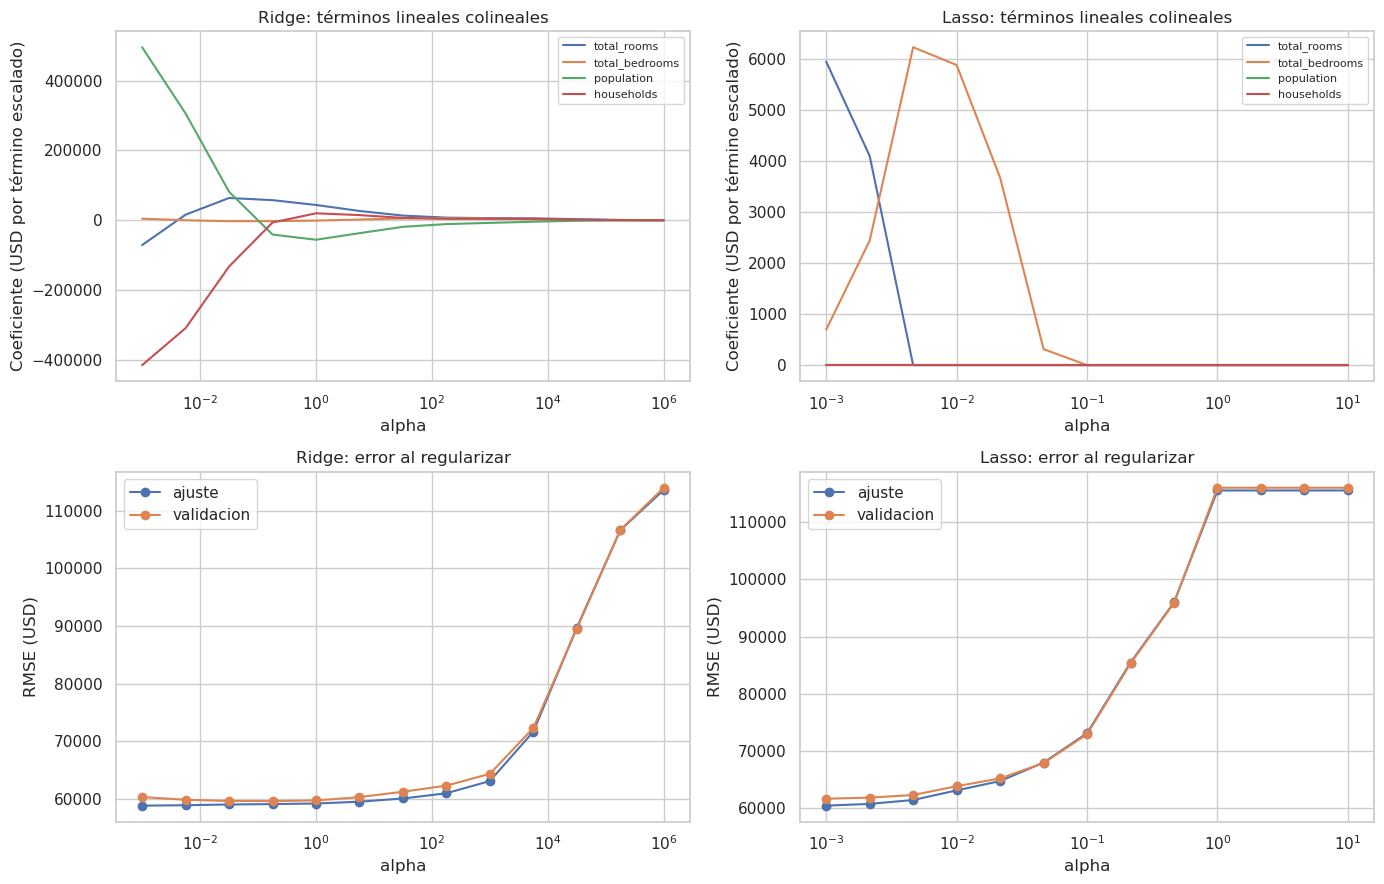

In [31]:
alphas_rutas = {'Ridge': np.logspace(-3, 6, 13), 'Lasso': np.logspace(-3, 1, 13)}
rutas_coef, rutas_errores = {}, {}
with warnings.catch_warnings(), threadpool_limits(limits=1):
    warnings.simplefilter('error', ConvergenceWarning)
    for metodo, alphas in alphas_rutas.items():
        coeficientes, errores = [], []
        for alpha in alphas:
            regresor = Ridge(alpha=alpha) if metodo == 'Ridge' else Lasso(alpha=alpha, max_iter=50_000, precompute=True)
            modelo = crear_modelo_polinomial(2, regresor).fit(X_ajuste, y_ajuste)
            beta = modelo.named_steps['modelo'].coef_
            coeficientes.append(beta)
            errores.append({
                'alpha': alpha,
                'ajuste': root_mean_squared_error(y_ajuste, modelo.predict(X_ajuste))*UNIDAD_Y,
                'validacion': root_mean_squared_error(y_validacion, modelo.predict(X_validacion))*UNIDAD_Y,
                'activos': np.count_nonzero(abs(beta) > 1e-8), 'norma_L2': np.linalg.norm(beta),
            })
        nombres_poly = modelo.named_steps['preparacion'].get_feature_names_out()
        rutas_coef[metodo] = pd.DataFrame(coeficientes, index=alphas, columns=nombres_poly)
        rutas_errores[metodo] = pd.DataFrame(errores).set_index('alpha')

variables_colineales = ['total_rooms', 'total_bedrooms', 'population', 'households']
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for columna, metodo in enumerate(['Ridge', 'Lasso']):
    for variable in variables_colineales:
        axes[0, columna].semilogx(rutas_coef[metodo].index, rutas_coef[metodo][variable]*UNIDAD_Y, label=variable)
    axes[0, columna].set(title=f'{metodo}: términos lineales colineales', xlabel='alpha', ylabel='Coeficiente (USD por término escalado)')
    axes[0, columna].legend(fontsize=8)
    for tipo in ['ajuste', 'validacion']:
        axes[1, columna].semilogx(rutas_errores[metodo].index, rutas_errores[metodo][tipo], 'o-', label=tipo)
    axes[1, columna].set(title=f'{metodo}: error al regularizar', xlabel='alpha', ylabel='RMSE (USD)')
    axes[1, columna].legend()
plt.tight_layout()
plt.show()
plt.close(fig)

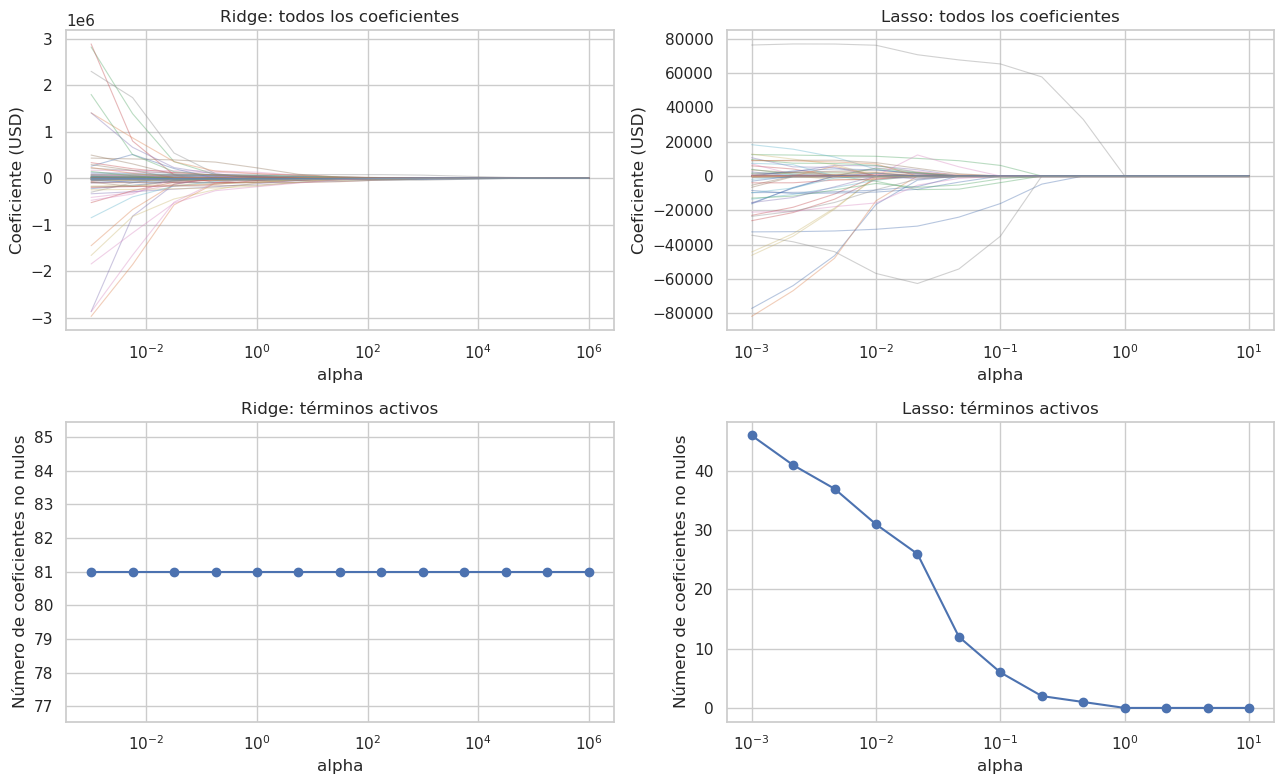

ajuste   validacion  activos  norma_L2
método alpha                                                      
Ridge  0.0010          58,820.6548  60,317.8144       81   80.7480
       0.0056          58,898.7695  59,841.7502       81   42.3221
       0.0316          59,022.8730  59,627.6330       81   15.3005
       0.1778          59,094.2115  59,615.3637       81    7.8555
       1.0000          59,191.6199  59,719.9764       81    5.4114
       5.6234          59,505.8010  60,305.0416       81    3.1954
       31.6228         60,063.0613  61,236.5105       81    1.8750
       177.8279        60,973.3471  62,298.4519       81    1.2841
       1,000.0000      63,095.7823  64,346.4569       81    0.9533
       5,623.4133      71,670.3910  72,304.9382       81    0.5950
       31,622.7766     89,734.7344  89,545.0921       81    0.2653
       177,827.9410   106,628.5298 106,668.4982       81    0.0791
       1,000,000.0000 113,629.4642 113,998.5420       81    0.0165
Lasso  0.0010          60,403.0306  61,613.6661       46    1.7212
       0.0022          60,711.1112  61,812.8330       41    1.5010
       0.0046          61,393.1170  62,264.7815       37    1.2596
       0.0100          63,077.2285  63,806.1238       31    1.0668
       0.0215          64,705.9649  65,178.7801       26    1.0156
       0.0464          67,952.9573  67,868.6324       12    0.9100
       0.1000          73,084.7033  72,899.1668        6    0.7616
       0.2154          85,462.3085  85,299.0251        2    0.5789
       0.4642          95,986.8676  95,904.2833        1    0.3295
       1.0000         115,578.1527 116,056.3395        0    0.0000
       2.1544         115,578.1527 116,056.3395        0    0.0000
       4.6416         115,578.1527 116,056.3395        0    0.0000
       10.0000        115,578.1527 116,056.3395        0    0.0000

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for columna, metodo in enumerate(['Ridge', 'Lasso']):
    axes[0, columna].semilogx(rutas_coef[metodo].index, rutas_coef[metodo].to_numpy()*UNIDAD_Y, alpha=0.4, linewidth=0.8)
    axes[0, columna].set(title=f'{metodo}: todos los coeficientes', xlabel='alpha', ylabel='Coeficiente (USD)')
    axes[1, columna].semilogx(rutas_errores[metodo].index, rutas_errores[metodo]['activos'], 'o-')
    axes[1, columna].set(title=f'{metodo}: términos activos', xlabel='alpha', ylabel='Número de coeficientes no nulos')
plt.tight_layout()
plt.show()
plt.close(fig)
display(pd.concat(rutas_errores, names=['método', 'alpha']))

### Diferencias entre L2 y L1

- **Ridge:** reduce continuamente los coeficientes y tiende a repartir peso entre variables correlacionadas. No hace una selección explícita de variables.
- **Lasso:** puede llevar coeficientes a cero. Ante variables muy correlacionadas puede conservar una y descartar otra; esa selección puede cambiar con pequeñas perturbaciones de los datos.
- Una penalización demasiado alta causa subajuste: ambos errores pueden empeorar. El punto útil no es el alpha que deja todos los coeficientes pequeños, sino el que generaliza mejor en validación.
- En este modelo polinomial, un término lineal en cero no implica que la variable desaparezca: puede seguir entrando mediante un cuadrado o una interacción. Por eso reviso también los nombres de todos los términos activos.

## 24.5. Selección final con GridSearchCV

Ahora selecciono **grado 1 o 2** y alpha mediante tres folds, solo dentro de `X_train`. Limito la búsqueda a estos grados por estabilidad y costo computacional después del experimento de alta complejidad. Imputadores, escaladores y creación de polinomios permanecen dentro del pipeline.

Uso RMSE como criterio común. El score de búsqueda es `neg_root_mean_squared_error`: sklearn maximiza su negativo, por eso lo cambio de signo al presentar los errores. No mezclo ese score con el $R^2$ que devuelve `LinearRegression.score`. La búsqueda es sobre una grilla finita, no garantiza el óptimo de todos los hiperparámetros posibles.

En los ensayos de entrenamiento, alpha muy cercano a cero dejó soluciones Lasso sin converger por la colinealidad de los términos. Por eso estudio alpha desde 0.001 y convierto cualquier advertencia de convergencia en un error: no oculto la advertencia ni comparo candidatos a medio optimizar. Esta restricción se basa en estabilidad numérica del entrenamiento, no en resultados de prueba.

In [33]:
grillas = {
    'Ridge': (Ridge(), np.logspace(-3, 4, 9)),
    'Lasso': (Lasso(max_iter=50_000, precompute=True), np.logspace(-3, 0, 9)),
}
busquedas = {}
with warnings.catch_warnings(), threadpool_limits(limits=1):
    warnings.simplefilter('error', ConvergenceWarning)
    for nombre, (regresor, alphas) in grillas.items():
        busqueda = GridSearchCV(
            crear_modelo_polinomial(2, regresor),
            param_grid={'preparacion__num__poly__degree': [1, 2], 'modelo__alpha': alphas},
            cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1,
            return_train_score=True, error_score='raise',
        )
        busqueda.fit(X_train, y_train)
        busquedas[nombre] = busqueda
        print(f'{nombre}: {busqueda.best_params_} | RMSE CV = {-busqueda.best_score_*UNIDAD_Y:,.0f} USD')
        resultados_grid = pd.DataFrame(busqueda.cv_results_)
        display(resultados_grid[['param_preparacion__num__poly__degree', 'param_modelo__alpha', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score').head())
        if np.isclose(busqueda.best_params_['modelo__alpha'], alphas[0]) or np.isclose(busqueda.best_params_['modelo__alpha'], alphas[-1]):
            print('Nota: alpha quedó en un borde de la grilla; se podría ampliar usando entrenamiento, nunca prueba.')
modelo_ridge = busquedas['Ridge'].best_estimator_
modelo_lasso = busquedas['Lasso'].best_estimator_
lasso_ajustado = modelo_lasso.named_steps['modelo']
print(f'Lasso: {lasso_ajustado.n_iter_} iteraciones; dual_gap={lasso_ajustado.dual_gap_:.3g}.')
assert lasso_ajustado.n_iter_ < lasso_ajustado.max_iter, 'Revisar convergencia antes de interpretar Lasso.'

Ridge: {'modelo__alpha': np.float64(0.4216965034285822), 'preparacion__num__poly__degree': 2} | RMSE CV = 60,309 USD


,param_preparacion__num__poly__degree,param_modelo__alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
7,2,0.4217,-0.5890,-0.6031,0.0044,1
5,2,0.0562,-0.5883,-0.6033,0.0046,2
3,2,0.0075,-0.5877,-0.6044,0.0065,3
9,2,3.1623,-0.5915,-0.6058,0.0042,4
1,2,0.0010,-0.5872,-0.6121,0.0173,5


Lasso: {'modelo__alpha': np.float64(0.001), 'preparacion__num__poly__degree': 2} | RMSE CV = 61,928 USD


,param_preparacion__num__poly__degree,param_modelo__alpha,mean_train_score,mean_test_score,std_test_score,rank_test_score
1,2,0.0010,-0.6024,-0.6193,0.0097,1
3,2,0.0024,-0.6073,-0.6218,0.0084,2
5,2,0.0056,-0.6173,-0.6285,0.0064,3
7,2,0.0133,-0.6371,-0.6448,0.0056,4
0,1,0.0010,-0.6580,-0.6605,0.0046,5


Nota: alpha quedó en un borde de la grilla; se podría ampliar usando entrenamiento, nunca prueba.
Lasso: 888 iteraciones; dual_gap=0.000103.


In [34]:
modelos_finales = {
    'Lineal': modelo_lineal, 'PCA': modelo_pca, 'Ridge': modelo_ridge, 'Lasso': modelo_lasso,
}
filas_cv = []
with threadpool_limits(limits=1):
    for nombre, modelo in modelos_finales.items():
        if nombre in busquedas:
            busqueda = busquedas[nombre]
            i = busqueda.best_index_
            media = -busqueda.cv_results_['mean_test_score'][i]
            desviacion = busqueda.cv_results_['std_test_score'][i]
        else:
            scores = cross_validate(clone(modelo), X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1)
            media, desviacion = -scores['test_score'].mean(), scores['test_score'].std()
        filas_cv.append({'Modelo': nombre, 'RMSE CV (USD)': media*UNIDAD_Y, 'Desv. CV (USD)': desviacion*UNIDAD_Y})
comparacion_cv = pd.DataFrame(filas_cv).set_index('Modelo')
modelo_elegido_cv = comparacion_cv['RMSE CV (USD)'].idxmin()
display(comparacion_cv)
print(f'Candidato elegido por RMSE CV ANTES de abrir prueba: {modelo_elegido_cv}.')
print('Las desviaciones entre folds no son intervalos de confianza. Los scores de los mejores hiperparámetros tienen sesgo de selección; prueba permite una evaluación posterior.')

,RMSE CV (USD),Desv. CV (USD)
Modelo,,
Lineal,"68,616.6870",301.3213
PCA,"86,306.3555","1,167.6373"
Ridge,"60,309.2151",440.0027
Lasso,"61,928.2316",965.3994


Candidato elegido por RMSE CV ANTES de abrir prueba: Ridge.
Las desviaciones entre folds no son intervalos de confianza. Los scores de los mejores hiperparámetros tienen sesgo de selección; prueba permite una evaluación posterior.


# 5.0 Comparación final — punto 25

## 25.1. Evaluar los cuatro modelos en la misma prueba

Recién ahora abro las etiquetas de prueba. Los modelos y sus hiperparámetros ya están fijados; no vuelvo a elegirlos según esta tabla. Todos predicen **los mismos distritos**, y calculo RMSE, MAE y $R^2$ con las mismas unidades.

Construyo `housing_test` con la preparación lineal ya ajustada en entrenamiento y su etiqueta en USD. PCA y los modelos polinomiales deben aplicar su **propia** preparación a esas mismas filas originales; no reciben por error la matriz MinMax del lineal. Verifico que la predicción del lineal desde el dataframe preparado coincida con la del pipeline.

In [35]:
X_test = strat_test_set.drop(columns=OBJETIVO)
y_test = strat_test_set[OBJETIVO] / UNIDAD_Y
housing_test = pd.DataFrame(
    preparacion_lineal.transform(agregar_variables(X_test)),
    columns=nombres_lineales, index=X_test.index,
)
housing_test[OBJETIVO] = strat_test_set[OBJETIVO]
assert housing_test.columns.equals(housing_train.columns)
assert housing_test.index.equals(X_test.index)
assert np.isfinite(housing_test.to_numpy()).all()

predicciones_test, filas_finales = {}, []
with threadpool_limits(limits=1):
    for nombre, modelo in modelos_finales.items():
        prediccion = modelo.predict(X_test)
        predicciones_test[nombre] = prediccion
        beta = modelo.named_steps['modelo'].coef_
        filas_finales.append({
            'Modelo': nombre, **metricas(y_test, prediccion),
            'Entradas al regresor': len(beta), 'Términos no nulos': np.count_nonzero(abs(beta) > 1e-8),
        })
comparacion_final = pd.DataFrame(filas_finales).set_index('Modelo')
np.testing.assert_allclose(
    modelo_lineal.named_steps['modelo'].predict(housing_test.drop(columns=OBJETIVO).to_numpy()),
    predicciones_test['Lineal'], atol=1e-10,
)
print('housing_train:', housing_train.shape, '| housing_test:', housing_test.shape)
display(comparacion_final)
print('El candidato sigue siendo el elegido por CV:', modelo_elegido_cv)
perdida_r2_test = comparacion_final.loc['Lineal', 'R2'] - comparacion_final.loc['PCA', 'R2']
print(f'Pérdida de R2 de PCA frente al lineal en prueba: {perdida_r2_test:+.4f}.')

housing_train: (16512, 16) | housing_test: (4128, 16)


,RMSE (USD),MAE (USD),R2,Entradas al regresor,Términos no nulos
Modelo,,,,,
Lineal,"66,803.1389","48,966.3085",0.6576,15,15
PCA,"84,162.3729","63,219.7077",0.4565,7,7
Ridge,"58,874.6745","41,682.6821",0.7340,81,81
Lasso,"59,925.6855","42,652.2364",0.7245,81,51


El candidato sigue siendo el elegido por CV: Ridge
Pérdida de R2 de PCA frente al lineal en prueba: +0.2011.


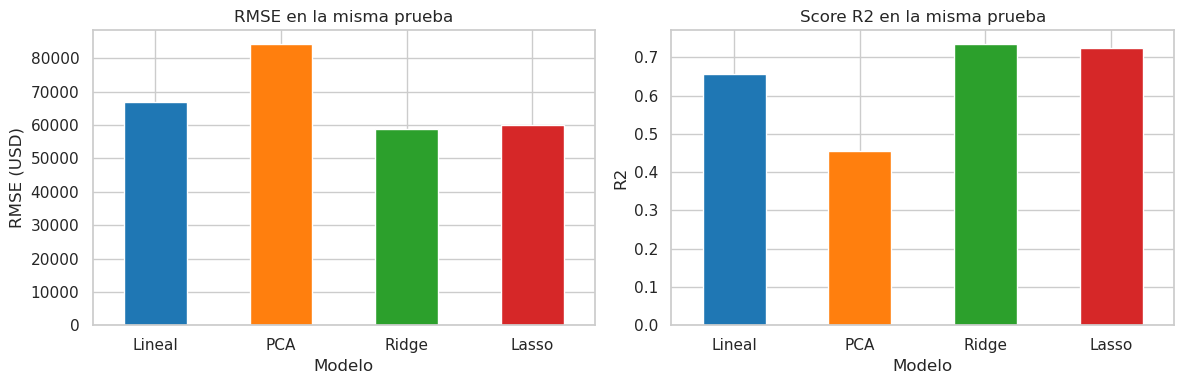

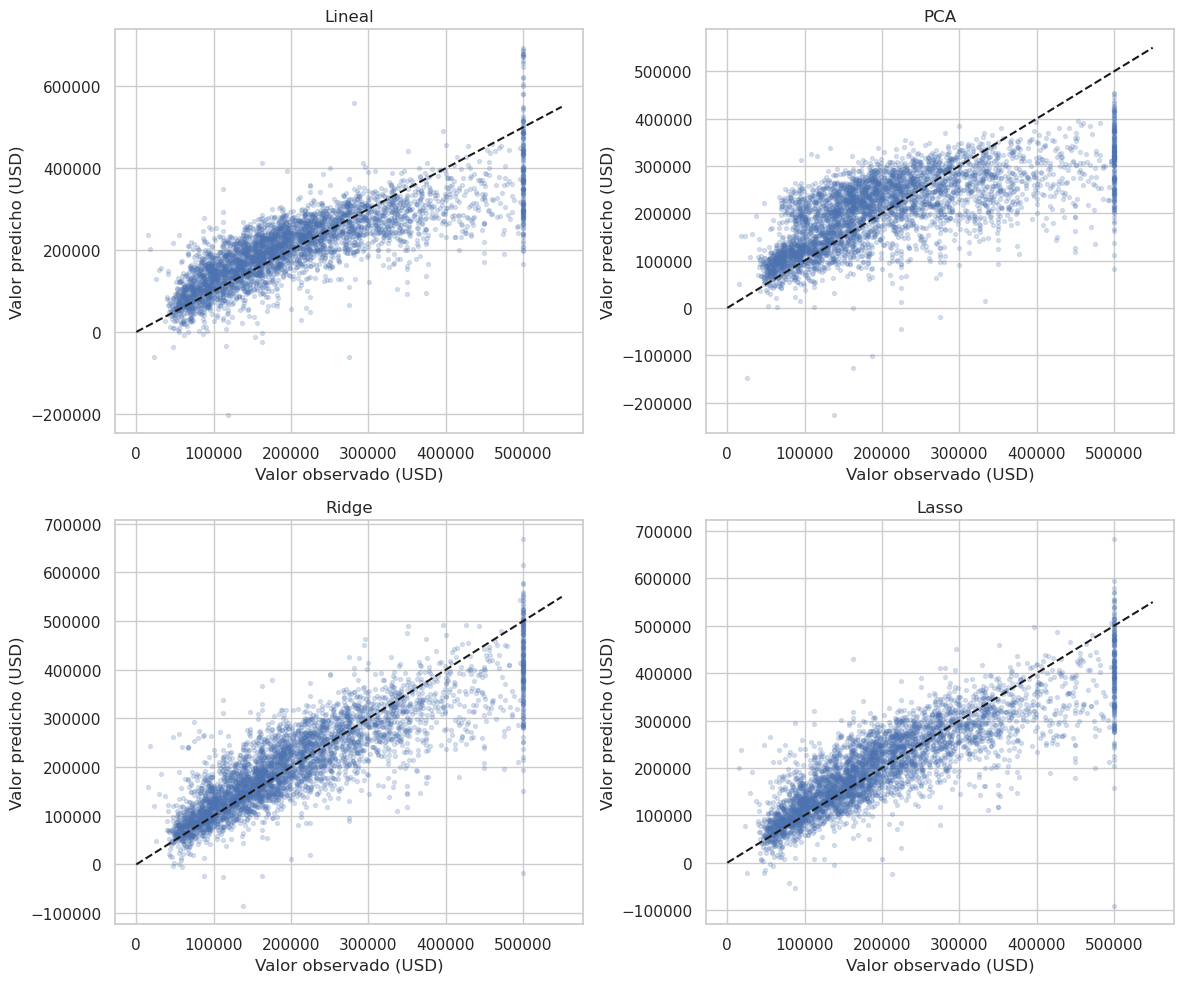

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparacion_final['RMSE (USD)'].plot.bar(ax=axes[0], color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])
axes[0].set(title='RMSE en la misma prueba', ylabel='RMSE (USD)', xlabel='Modelo')
comparacion_final['R2'].plot.bar(ax=axes[1], color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])
axes[1].set(title='Score R2 en la misma prueba', ylabel='R2', xlabel='Modelo')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (nombre, prediccion) in zip(axes.ravel(), predicciones_test.items()):
    ax.scatter(y_test*UNIDAD_Y, prediccion*UNIDAD_Y, s=8, alpha=0.2)
    ax.plot([0, 550_000], [0, 550_000], 'k--')
    ax.set(title=nombre, xlabel='Valor observado (USD)', ylabel='Valor predicho (USD)')
plt.tight_layout()
plt.show()
plt.close(fig)

## 25.2. Bootstrap pareado de las diferencias

Remuestreo **filas de prueba con reemplazo**, usando los mismos índices para los cuatro modelos en cada réplica. Así conservo el emparejamiento entre errores. Defino

$$\Delta RMSE=RMSE_{modelo}-RMSE_{lineal}.$$

Un valor negativo favorece al modelo alternativo. Obtengo un intervalo percentil nominal del 95%; si contiene cero no tengo evidencia suficiente de una diferencia. Además reporto un intervalo **98.33% por comparación**, usando Bonferroni para las tres comparaciones con el lineal (control aproximado del 5% familiar). Uso este intervalo ajustado para la conclusión de significancia.

Los modelos **no se reentrenan** en este bootstrap. Los intervalos describen incertidumbre del desempeño de modelos ya ajustados, condicional a esta partición; no incorporan la variabilidad de todo el entrenamiento. El remuestreo supone distritos independientes: por dependencia espacial, estas conclusiones son aproximadas y sería preferible un bootstrap por bloques para una aplicación real.

In [37]:
rng_bootstrap = np.random.default_rng(SEED)
nombres_modelos = list(modelos_finales)
y_prueba_array = y_test.to_numpy()
errores_cuadrados = np.column_stack([(y_prueba_array - predicciones_test[nombre])**2 for nombre in nombres_modelos])
rmse_bootstrap = np.empty((N_BOOTSTRAP, len(nombres_modelos)))
for b in range(N_BOOTSTRAP):
    indices = rng_bootstrap.integers(0, len(y_test), size=len(y_test))
    rmse_bootstrap[b] = np.sqrt(errores_cuadrados[indices].mean(axis=0))*UNIDAD_Y

cola_ajustada = 0.05 / (2 * 3)
filas_bootstrap = []
for j, nombre in enumerate(nombres_modelos[1:], start=1):
    diferencias = rmse_bootstrap[:, j] - rmse_bootstrap[:, 0]
    inferior, superior = np.quantile(diferencias, [0.025, 0.975])
    inferior_aj, superior_aj = np.quantile(diferencias, [cola_ajustada, 1-cola_ajustada])
    conclusion = 'Mejora respecto al lineal' if superior_aj < 0 else ('Empeora respecto al lineal' if inferior_aj > 0 else 'Diferencia no concluyente')
    filas_bootstrap.append({
        'Modelo': nombre,
        'Delta RMSE (USD)': comparacion_final.loc[nombre, 'RMSE (USD)'] - comparacion_final.loc['Lineal', 'RMSE (USD)'],
        'IC95 inferior': inferior, 'IC95 superior': superior,
        'IC98.33 inferior': inferior_aj, 'IC98.33 superior': superior_aj,
        'Conclusión ajustada': conclusion,
    })
comparacion_bootstrap = pd.DataFrame(filas_bootstrap).set_index('Modelo')
display(comparacion_bootstrap)
display(pd.DataFrame(np.quantile(rmse_bootstrap, [0.025, 0.975], axis=0).T, index=nombres_modelos, columns=['RMSE IC95 inferior (USD)', 'RMSE IC95 superior (USD)']))

,Delta RMSE (USD),IC95 inferior,IC95 superior,IC98.33 inferior,IC98.33 superior,Conclusión ajustada
Modelo,,,,,,
PCA,"17,359.2340","15,654.1874","19,003.8401","15,222.6879","19,310.7315",Empeora respecto al lineal
Ridge,"-7,928.4644","-9,421.4248","-6,198.7227","-9,792.8646","-5,793.6539",Mejora respecto al lineal
Lasso,"-6,877.4534","-8,437.9287","-5,015.2940","-8,709.9647","-4,399.6016",Mejora respecto al lineal


,RMSE IC95 inferior (USD),RMSE IC95 superior (USD)
Lineal,"64,523.8984","68,876.2356"
PCA,"81,691.2455","86,595.3509"
Ridge,"56,753.2579","61,125.4654"
Lasso,"57,653.6243","62,314.0394"


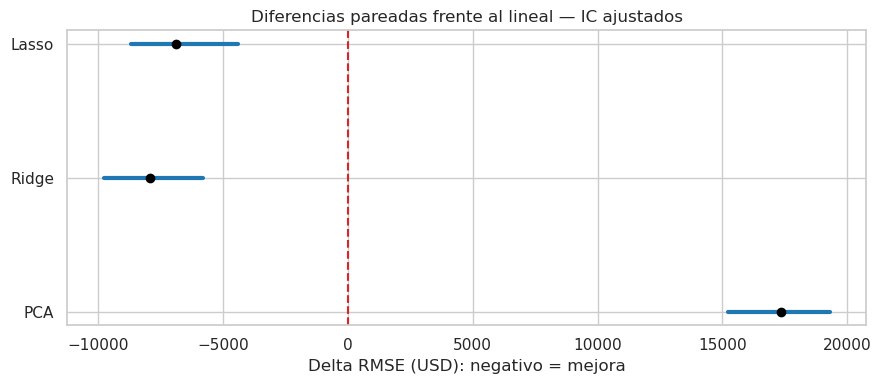

In [38]:
fig, ax = plt.subplots(figsize=(9, 4))
for posicion, (nombre, fila) in enumerate(comparacion_bootstrap.iterrows()):
    ax.plot([fila['IC98.33 inferior'], fila['IC98.33 superior']], [posicion, posicion], linewidth=3, color='tab:blue')
    ax.scatter(fila['Delta RMSE (USD)'], posicion, color='black', zorder=3)
ax.axvline(0, color='tab:red', linestyle='--')
ax.set_yticks(range(3), comparacion_bootstrap.index)
ax.set(title='Diferencias pareadas frente al lineal — IC ajustados', xlabel='Delta RMSE (USD): negativo = mejora')
plt.tight_layout()
plt.show()
plt.close(fig)

## 25.3. ¿Lasso conserva las mismas variables que destaca PCA?

No necesariamente. PCA es **no supervisado**: resume varianza de las entradas, incluso si esa varianza no ayuda a predecir el precio. Lasso es **supervisado**: conserva términos que ayudan a predecir bajo su penalización. Puede eliminar un término redundante aunque la variable tenga una carga grande en PCA.

Para compararlos correctamente agrego la participación de cada variable en las tres componentes y reviso si aparece en algún término activo de Lasso, incluyendo cuadrados e interacciones. La suma de cuadrados de los pesos de PCA representa cuánto participa la variable en el subespacio retenido; no es una importancia predictiva.

In [39]:
pre_lasso = modelo_lasso.named_steps['preparacion']
nombres_lasso = pre_lasso.get_feature_names_out()
beta_lasso = modelo_lasso.named_steps['modelo'].coef_
activos_lasso = abs(beta_lasso) > 1e-8
terminos_lasso = pd.DataFrame({'termino': nombres_lasso, 'coeficiente (USD)': beta_lasso*UNIDAD_Y, 'activo': activos_lasso})
display(terminos_lasso.loc[terminos_lasso.activo].sort_values('coeficiente (USD)', key=lambda s: s.abs(), ascending=False).head(20))

poly_lasso = pre_lasso.named_transformers_['num'].named_steps['poly']
potencias = poly_lasso.powers_
activos_numericos = activos_lasso[:len(potencias)]
aparece_en_activo = (potencias[activos_numericos] > 0).any(axis=0)
participacion_pca = (pca_final.components_**2).sum(axis=0)
relacion_lasso_pca = pd.DataFrame({
    'Participación subespacio PCA': participacion_pca,
    'Lasso: aparece en algún término activo': aparece_en_activo,
}, index=NUMERICAS).sort_values('Participación subespacio PCA', ascending=False)
display(relacion_lasso_pca)
print(f'Lasso conserva {activos_lasso.sum()} de {len(activos_lasso)} términos y utiliza {aparece_en_activo.sum()} de {len(NUMERICAS)} variables numéricas en algún término.')
print('Si conserva casi todas las variables, no lo voy a presentar como un modelo realmente pequeño solo por usar L1.')

,termino,coeficiente (USD),activo
1,latitude,"-83,919.9450",True
0,longitude,"-78,635.2691",True
7,median_income,"78,268.3801",True
28,latitude median_income,"-50,065.0742",True
18,longitude median_income,"-46,570.5730",True
77,ocean_proximity_INLAND,"-32,440.0674",True
10,population_per_household,"-31,508.8415",True
67,median_income^2,"-25,929.4445",True
23,latitude housing_median_age,"-25,601.6764",True
13,longitude housing_median_age,"-22,507.4404",True


,Participación subespacio PCA,Lasso: aparece en algún término activo
latitude,0.4967,True
longitude,0.4921,True
bedrooms_per_room,0.3741,True
median_income,0.3421,True
households,0.2550,True
total_rooms,0.2512,True
total_bedrooms,0.2506,True
population,0.2298,True
rooms_per_household,0.2282,True
housing_median_age,0.0801,True


Lasso conserva 51 de 81 términos y utiliza 11 de 11 variables numéricas en algún término.
Si conserva casi todas las variables, no lo voy a presentar como un modelo realmente pequeño solo por usar L1.


## 25.4. Volver a responder los puntos 18–20

**18. Conclusión sobre el modelo.** La regresión inicial sigue siendo una referencia útil, pero la tabla final muestra cuánto cambia el error con otras representaciones y penalizaciones. Los intervalos pareados permiten separar una diferencia respaldada por este remuestreo de una variación no concluyente. No reajusto los candidatos con esta información de prueba.

**19. Validez.** El lineal no deja de ser un predictor válido por perder frente a otro modelo; sí puede ser insuficiente para describir relaciones no lineales. Ridge/Lasso son lineales en sus coeficientes, pero con polinomios son no lineales en las variables originales. Su posible mejora combina una representación más flexible y regularización: no atribuyo toda la mejora frente al lineal exclusivamente a L1/L2. El experimento de grado 4 sí aisló el efecto de penalizar sobre una misma representación.

**20. Score.** $R^2$ permite comparar cuánta variación del precio se explica respecto a la media, siempre usando las mismas filas. No demuestra causalidad ni garantiza errores pequeños en todos los grupos. Por eso acompaño el score con RMSE/MAE en USD, gráficos de predicción e incertidumbre.

**Interpretabilidad.** PCA reduce de 11 a 3 numéricas pero mezcla sus significados. Lasso puede simplificar términos, aunque no necesariamente variables originales. Para comunicar una predicción a una persona no especialista puedo usar el candidato elegido por CV y explicar el error típico y sus límites, sin obligarla a interpretar cada interacción. Si necesita una ecuación sencilla, mostraría el lineal como referencia y haría explícito cuánto rendimiento pierde. No llamaría a una carga de PCA ni a un coeficiente una causa del precio.

In [40]:
fila_lineal = comparacion_final.loc['Lineal']
fila_pca = comparacion_final.loc['PCA']
fila_elegido = comparacion_final.loc[modelo_elegido_cv]
resumen = f'''### Resumen de esta ejecución

- La regresión lineal obtiene **R² = {fila_lineal['R2']:.3f}**, RMSE **{fila_lineal['RMSE (USD)']:,.0f} USD** y MAE **{fila_lineal['MAE (USD)']:,.0f} USD** en prueba.
- El reducido conserva **3 componentes + 4 indicadores**, con R² **{fila_pca['R2']:.3f}**. Frente al lineal pierde **{fila_lineal['R2']-fila_pca['R2']:+.3f} puntos de R²** y cambia el RMSE en **{fila_pca['RMSE (USD)']-fila_lineal['RMSE (USD)']:+,.0f} USD**.
- Las permutaciones dan **p = {p_permutacion:.3f}**: la evidencia se interpreta bajo intercambiabilidad de etiquetas, no como causalidad.
- El candidato elegido **antes de prueba** por CV es **{modelo_elegido_cv}**. Su RMSE de prueba es **{fila_elegido['RMSE (USD)']:,.0f} USD**, {fila_lineal['RMSE (USD)']-fila_elegido['RMSE (USD)']:,.0f} USD menos que el lineal.
'''
for nombre, fila in comparacion_bootstrap.iterrows():
    resumen += '- **{}:** {}, con intervalo ajustado de ΔRMSE **[{:,.0f}, {:,.0f}] USD**.\n'.format(nombre, fila['Conclusión ajustada'], fila['IC98.33 inferior'], fila['IC98.33 superior'])
resumen += '\nPresentaría el candidato elegido por CV como opción predictiva y el lineal como referencia explicable. Estos errores corresponden a distritos de una base histórica, no a tasaciones actuales ni a casas individuales.'
display(Markdown(resumen))

### Resumen de esta ejecución

- La regresión lineal obtiene **R² = 0.658**, RMSE **66,803 USD** y MAE **48,966 USD** en prueba.
- El reducido conserva **3 componentes + 4 indicadores**, con R² **0.457**. Frente al lineal pierde **+0.201 puntos de R²** y cambia el RMSE en **+17,359 USD**.
- Las permutaciones dan **p = 0.005**: la evidencia se interpreta bajo intercambiabilidad de etiquetas, no como causalidad.
- El candidato elegido **antes de prueba** por CV es **Ridge**. Su RMSE de prueba es **58,875 USD**, 7,928 USD menos que el lineal.
- **PCA:** Empeora respecto al lineal, con intervalo ajustado de ΔRMSE **[15,223, 19,311] USD**.
- **Ridge:** Mejora respecto al lineal, con intervalo ajustado de ΔRMSE **[-9,793, -5,794] USD**.
- **Lasso:** Mejora respecto al lineal, con intervalo ajustado de ΔRMSE **[-8,710, -4,400] USD**.

Presentaría el candidato elegido por CV como opción predictiva y el lineal como referencia explicable. Estos errores corresponden a distritos de una base histórica, no a tasaciones actuales ni a casas individuales.

# 6.0 Comunicación, uso del modelo y reproducibilidad

## Deployment y monitoreo

No despliego una API en este laboratorio. El siguiente ejemplo muestra que el pipeline final recibe las columnas originales; las funciones y transformaciones aprendidas deben viajar junto con el regresor si se exporta. Para producción habría que empaquetar también las funciones de ingeniería y fijar versiones.

Monitorearía esquema de columnas, categorías nuevas, valores faltantes, rangos y distribución de las entradas. Con etiquetas recientes, también el error y su comportamiento por región. Un cambio en $P(X)$ no garantiza deterioro y la ausencia de cambio visible no garantiza buen desempeño: también puede cambiar $P(y\mid X)$. Esta base de 1990 no permite medir drift temporal ni afirmar validez para el mercado actual.

In [41]:
# Ejemplo de interfaz, no evaluación adicional: tres distritos de entrenamiento.
nuevas_entradas_ejemplo = X_train.head(3).copy()
modelo_para_uso = modelos_finales[modelo_elegido_cv]
resultado_ejemplo = nuevas_entradas_ejemplo.copy()
resultado_ejemplo['prediccion_USD'] = modelo_para_uso.predict(nuevas_entradas_ejemplo)*UNIDAD_Y
display(resultado_ejemplo)
print('No son datos de producción y este ejemplo no estima un intervalo predictivo individual.')

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,prediccion_USD
12655,-121.4600,38.5200,29.0000,"3,873.0000",797.0000,"2,237.0000",706.0000,2.1736,INLAND,"75,667.8803"
15502,-117.2300,33.0900,7.0000,"5,320.0000",855.0000,"2,015.0000",768.0000,6.3373,NEAR OCEAN,"293,187.5370"
2908,-119.0400,35.3700,44.0000,"1,618.0000",310.0000,667.0000,300.0000,2.8750,INLAND,"166,526.7985"


No son datos de producción y este ejemplo no estima un intervalo predictivo individual.


## Limitaciones y próximos pasos

- Los precios y algunas características tienen topes; el error cerca de esos límites requiere cuidado.
- El muestreo por ingreso conserva ese balance, pero no elimina dependencia espacial ni desequilibrios en `ISLAND`.
- La imputación no demuestra que los faltantes sean completamente aleatorios.
- El test de permutaciones y el bootstrap por filas suponen intercambiabilidad/independencia; una validación geográfica y remuestreo por bloques serían más realistas para otra región.
- Las búsquedas son pequeñas y sus mejores scores de CV son optimistas por selección; la prueba se reserva para la comparación final. No ampliaría una grilla a partir del resultado de prueba.
- Los intervalos de RMSE son de desempeño agregado, **no intervalos de confianza de una predicción individual**.
- Antes de uso real, necesitaría datos recientes, validación externa, análisis de errores por grupos y monitoreo.

## Cómo reproducir

Ejecutar todas las celdas en orden desde un kernel nuevo con Python y `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`, `IPython` y `threadpoolctl`. Las semillas están fijadas en 42; el CSV y su hash, las versiones, particiones, grillas y número de réplicas quedan registrados. No se necesita ningún archivo de los Labs 01–04, instalar un paquete propio ni cambiar de rama. Las tablas de conclusiones se calculan a partir de los resultados, no de cifras escritas de antemano.

In [42]:
import matplotlib
import scipy

registro = {
    'semilla': SEED, 'fuente': URL, 'sha256_csv': sha256_datos,
    'filas_ajuste': len(X_ajuste), 'filas_validacion': len(X_validacion), 'filas_test': len(X_test),
    'folds_CV': cv.n_splits, 'componentes_PCA': K_PCA,
    'permutaciones': N_PERMUTACIONES, 'replicas_bootstrap': N_BOOTSTRAP,
    'criterio_seleccion': 'RMSE CV antes de prueba', 'modelo_elegido': modelo_elegido_cv,
    'Python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__,
    'sklearn': sklearn.__version__, 'scipy': scipy.__version__,
}
display(pd.Series(registro, name='Valor').to_frame())
assert len(comparacion_final) == 4
assert len(comparacion_bootstrap) == 3
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_ajuste.index) | set(X_validacion.index) == set(X_train.index)
assert all(np.isfinite(pred).all() for pred in predicciones_test.values())
assert all(len(pred) == len(y_test) for pred in predicciones_test.values())
assert len(pca_final.components_) == K_PCA
assert len(scores_permutados) == N_PERMUTACIONES
assert rmse_bootstrap.shape == (N_BOOTSTRAP, 4)
print('Verificaciones finales correctas: mismas filas de prueba, etiquetas fuera de características y cuatro modelos comparables.')

,Valor
semilla,42
fuente,https://raw.githubusercontent.com/hernansalina...
sha256_csv,8a3727f4cf54ac1a327f69b1d5b4db54c5834ea81c6e4e...
filas_ajuste,12384
filas_validacion,4128
filas_test,4128
folds_CV,3
componentes_PCA,3
permutaciones,199
replicas_bootstrap,3000


Verificaciones finales correctas: mismas filas de prueba, etiquetas fuera de características y cuatro modelos comparables.
